# Cross-chain vault-of-vaults with a refreshed universe and $3,000 bridge buffer

Based on `../xchain2/47-backtest-tail-gate-12-positions-tuned.ipynb` (NB47). This variant retains its allocation and ranking parameters and the 1 April 2025 start, refreshes the source vaults using the existing universe rules, and runs through 20 October 2026 inclusive (exclusive end: 21 October).

The first xchain3 run (`01-backtest-tail-gate-12-positions-refreshed-universe.ipynb`) failed with `NotEnoughMoney`: primary-chain bridge funding needed $1,900.04 but only the $1,000 buffer was available. This variant raises `cross_chain_cash_buffer_usd` to $3,000, leaving the other strategy parameters unchanged. This is an operational funding adjustment, with an expected return cost from holding more cash.

## Universe refresh

Metadata generated at **2026-10-21T09:40:40Z**, refreshed on 21 October 2026. The frozen source list contains **356 vaults**, versus 350 in NB47: **87 added, 81 removed, 269 retained**.

- Chains: Ethereum, Base, Arbitrum, Avalanche, HyperEVM and Monad; each vault must accept its chain-native USDC contract.
- Lagoon, IPOR Fusion, Ember, Gains Network and Fluid: current TVL at least $50,000.
- Include all native-USDC Yearn, 40acres, YieldNest, Plutus, Upshift and auto.finance vaults, plus Hyperithm, Sky, Sentora and kpk curated vaults.
- Include Morpho vaults only without red or yellow Morpho display flags. Exclude explicit subvaults, legacy Yearn Compounders, cSigma and explicit non-zero deposit or withdrawal fees.
- Preserve the Arbitrum Fluid queue venue and D2 HYPE++ directional vault. Historical availability checks and the inherited synthetic D2 windows govern execution; present-day temporary deposit closures do not erase historical candidates.
- Incomplete-fee, whitelist-gated and producer-blacklisted records remain diagnostic-only under the inherited runtime guards. Historical allocation still requires $50,000 TVL and all strategy eligibility checks.

The strategy targets twelve positions with a 5% allocation floor, a 10% base concentration cap and a 20% adaptive ceiling. It ranks by fee-adjusted 90-day CAGR, refreshes membership weekly, and retains the -0.5% trailing 180-day drawdown and -1.5% worst daily return gates. The 95% allocation target leaves a nominal 5% cash reserve; idle excess earns yield in Fluid.

## Key new insights and what we learnt from this experiment

- The unchanged NB47 bridge buffer is insufficient after the universe refresh: the first run required $1,900.04 against $1,000 available. A $3,000 buffer completes the full period with every CCTP bridge successful. This is an execution-funding adjustment, not a parameter search for better returns.
- With the refreshed universe and larger buffer, $100,000 grows to **$117,332.90**: **17.33% total return, 10.84% CAGR and 11.33 Sharpe**. NB47's recorded shorter-window result was 10.53% CAGR and 9.02 Sharpe; the universe, cash buffer, source data and evaluation end all differ, so the comparison does not isolate a cause.
- The refreshed strategy had $115,172.63 at 31 August 2026 and gained a further **$2,160.27 / 1.88%** through 20 October. This extension uses the current universe snapshot and is not an untouched holdout.
- Profit is distributed across **51 distinct vaults**. The largest contributor is HYPE++ at $2,189.07, followed by Plutus Hedge Token ($1,644.06), Aerodrome USDC ($1,492.99), Pharaoh USDC ($1,348.36) and Syntropia Boosted ($904.71). The top one, three and five account for 12.63%, 30.73% and 43.73% of positive vault PnL.

## Summary of results

Executed successfully through **20 October 2026**, covering 1 April 2025 onwards. All **21 code cells completed without errors**; saved charts and diagnostics are included below.

| Metric | Result |
| --- | ---: |
| Initial / final equity | $100,000 / $117,332.90 |
| Total return / CAGR | 17.33% / 10.84% |
| Sharpe / Sortino | 11.33 / 101.45 |
| Maximum drawdown / longest drawdown | -0.12% / 6 days |
| Annualised volatility | 0.91% |
| Best / worst day | +0.71% / -0.12% |
| Daily-return kurtosis | 85.55 |
| Total / vault trades | 713 / 540 |
| Successful CCTP bridges | 173 of 173 |
| Vault turnover | $1,708,147.77 |
| Vault positions / median holding time | 69 / 70 days |
| Vaults with negative aggregate PnL | 0 of 51 traded |
| Final raw cash / pending positions | $5,863.66 / 0 |

The source snapshot contains 356 vaults. Runtime construction produces 355 vault pairs, including 122 ignored diagnostic-only pairs (233 not ignored); Tori Ecosystem Vault has no price history. The ignored sets overlap: 94 producer-blacklisted vaults, 28 whitelist-gated vaults and 11 with incomplete fee metadata.

## Robustness of results

- **NAV smoothing materially affects the risk statistics.** The best portfolio day, 6 June 2025 (+0.7052%), includes $699.68 of HYPE++ PnL, about 98% of that day's position-PnL changes. Actual HYPE++ observations jump from a $1.200659 share price on 6 May to $1.309755 on 6 June, with no intervening observations. The apparent daily gain therefore spans a month of missing NAV observations. HYPE++ supplies only 12.63% of total positive vault PnL, so the overall result is not a single-jump result, but Sharpe, volatility and drawdown remain sensitive to stale NAV marking. Kurtosis is still extreme at 85.55.
- **Zero negative aggregate vault PnL does not mean no losses occurred.** On the worst day, 5 February 2026, Hub Capital contributes -$137.56; it nevertheless finishes positive in aggregate. The inherited valuation-update-only diagnostic is empty, so the additional position-statistics attribution below is used rather than interpreting the empty table as evidence of no jumps.
- **Current metadata introduces selection bias.** The 21 October catalogue, flags and fee treatment apply to the historical period, including 94 producer-blacklisted diagnostic-only vaults. The refreshed sources and longer period are not a point-in-time reconstruction. Today’s protocol and curator membership must not be interpreted as information known in 2025.
- **Source freshness is uneven.** Actual observations extend through 20 October at 23:12:59 UTC; 304 of 356 sources have an observation that day, while five have none in the final fortnight. Forward-filled candles do not supply independent evidence of freshness. The strategy retains its inherited staleness and availability checks.
- **Settlement and liquidity assumptions remain inherited.** Vault trades fill at share-price NAV without deposit/redemption slippage. HYPE++ uses synthetic fortnightly windows and some async vaults use estimated settlement delays rather than historical settlement events. The inherited curator expansion also admits Accountable vaults despite the shared curator's current illiquidity exclusion; the two traded Accountable vaults contribute $835.96 combined. Their real liquidity needs separate validation.
- **The 10% concentration cap is a base cap.** It rises above 10% on 59 of 568 daily diagnostics and reaches 16.67% with six freely allocatable members. The configured ceiling remains 20%.
- **Operational checks passed for this configuration.** No ignored vault was traded, all 173 bridges succeeded, final raw cash is approximately 5% of equity, and no pending positions remain. The $1,000-buffer failure is preserved separately rather than suppressed.


## Notebook setup

Imports, Trading Strategy client and charting setup.


In [1]:
import datetime
import logging
import os
import re

import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import display
from dotenv import load_dotenv
from eth_defi.token import USDC_NATIVE_TOKEN
from plotly.graph_objects import Figure
from tradingstrategy.chain import ChainId
from tradingstrategy.client import Client
from tradingstrategy.timebucket import TimeBucket
from tradingstrategy.utils.token_filter import filter_for_selected_pairs

from tradeexecutor.analysis.vault import (
    BLACKLISTED_VAULT_DIAGNOSTIC_FLAG,
    WHITELISTED_VAULT_DIAGNOSTIC_FLAG,
    mark_whitelisted_vaults_ignored,
    render_blacklisted_vaults,
    render_whitelisted_vaults,
)
from tradeexecutor.backtest.backtest_runner import run_backtest_inline
from tradeexecutor.curator import is_quarantined
from tradeexecutor.ethereum.vault.checks import check_stale_vault_data
from tradeexecutor.exchange_account.allocation import (
    calculate_portfolio_target_value,
    get_redeemable_portfolio_capital,
)
from tradeexecutor.state.identifier import TradingPairIdentifier
from tradeexecutor.state.trade import TradeExecution
from tradeexecutor.state.types import USDollarAmount
from tradeexecutor.strategy.alpha_model import AlphaModel
from tradeexecutor.strategy.chart.definition import ChartInput, ChartKind, ChartRegistry
from tradeexecutor.strategy.chart.standard.alpha_model import (
    alpha_model_diagnostics,
    missed_vault_deposit_redemption_events,
    missed_vault_deposit_redemption_timeline,
)
from tradeexecutor.strategy.chart.standard.equity_curve import (
    equity_curve as equity_curve_chart,
    equity_curve_with_drawdown,
)
from tradeexecutor.strategy.chart.standard.interest import vault_statistics
from tradeexecutor.strategy.chart.standard.performance_metrics import (
    performance_metrics,
)
from tradeexecutor.strategy.chart.standard.position import positions_at_end
from tradeexecutor.strategy.chart.standard.profit_breakdown import (
    trading_pair_breakdown,
)
from tradeexecutor.strategy.chart.standard.thinking import last_messages
from tradeexecutor.strategy.chart.standard.trading_metrics import trading_metrics
from tradeexecutor.strategy.chart.standard.trading_universe import (
    available_trading_pairs,
    ignored_vault_data,
    inclusion_criteria_check,
)
from tradeexecutor.strategy.chart.standard.vault import (
    all_vault_positions,
    pending_trigger_queue,
    pending_vault_settlements,
    vault_settlement_observations,
    phase_aware_queue_duration,
    phase_aware_queue_duration_summary,
)
from tradeexecutor.strategy.chart.standard.weight import (
    equity_curve_by_asset,
    equity_curve_by_asset_with_legend,
    equity_curve_by_chain,
    equity_curve_by_liquidity_state,
    weight_allocation_statistics,
)
from tradeexecutor.strategy.cycle import CycleDuration
from tradeexecutor.strategy.default_routing_options import TradeRouting
from tradeexecutor.strategy.execution_context import (
    ExecutionContext,
    ExecutionMode,
    notebook_execution_context,
)
from tradeexecutor.strategy.pandas_trader.indicator import (
    IndicatorDependencyResolver,
    IndicatorSource,
    calculate_and_load_indicators_inline,
)
from tradeexecutor.strategy.pandas_trader.indicator_decorator import IndicatorRegistry
from tradeexecutor.strategy.pandas_trader.strategy_input import StrategyInput
from tradeexecutor.strategy.pandas_trader.trading_universe_input import (
    CreateTradingUniverseInput,
)
from tradeexecutor.strategy.parameters import StrategyParameters
from tradeexecutor.strategy.reserve_currency import ReserveCurrency
from tradeexecutor.strategy.tag import StrategyTag
from tradeexecutor.strategy.trading_strategy_universe import (
    TradingStrategyUniverse,
    load_partial_data,
    load_vault_universe_with_metadata,
)
from tradeexecutor.strategy.chart.renderer import ChartBacktestRenderingSetup
from tradeexecutor.strategy.vault_fee_data import mark_missing_fee_vaults_ignored
from tradeexecutor.strategy.tvl_size_risk import USDTVLSizeRiskModel
from tradeexecutor.strategy.universe_model import UniverseOptions
from tradeexecutor.utils.dedent import dedent_any
from tradeexecutor.utils.notebook import (
    OutputMode,
    display_head_and_tail,
    setup_charting_and_output,
)
from tradeexecutor.visual.equity_curve import calculate_equity_curve, calculate_returns

from tradeexecutor.backtest.vault_windows import VaultWindowSchedule
from tradeexecutor.strategy.pandas_trader.yield_manager import (
    YieldDecisionInput,
    YieldManager,
    YieldRuleset,
    YieldWeightingRule,
)
from tradeexecutor.strategy.phase_aware import (
    PhaseAwareAlphaModel,
    queue_vault_pair_ids,
)

load_dotenv(override=True)
setup_charting_and_output(OutputMode.static, image_format="png", width=1500, height=900)

api_key = os.environ.get("TRADING_STRATEGY_API_KEY")
# Vaults Pro (Creem) licence key. Optional here: create_jupyter_client(needs_vault_data=True)
# also reads VAULT_PRO_API_KEY / the saved settings file / prompts, but passing it explicitly
# overrides a wrong or expired stored key.
vault_pro_api_key = os.environ.get("VAULT_PRO_API_KEY")
client = Client.create_jupyter_client(
    api_key=api_key,
    needs_vault_data=True,
    vault_pro_api_key=vault_pro_api_key,
)
logger = logging.getLogger("strategy")

trading_strategy_engine_version = "0.5"


Started Trading Strategy in Jupyter notebook environment, configuration is stored in /Users/moo/.tradingstrategy


## Parameters

Strategy parameters and the phase-aware queue venue configuration.


In [2]:
class Parameters:
    id = "xchain3-tail-gate-refreshed-3000-buffer-2026-10-20"

    # Data and rebalance cadence
    candle_time_bucket = TimeBucket.d1
    cycle_duration = CycleDuration.cycle_1d
    data_history_start = datetime.datetime(2024, 6, 1)
    backtest_start = datetime.datetime(2025, 4, 1)
    backtest_end = datetime.datetime(2026, 10, 21)
    initial_cash = 100_000

    # Cross-chain native-USDC vault universe
    chain_id = ChainId.cross_chain
    primary_chain_id = ChainId.arbitrum
    preferred_stablecoin = USDC_NATIVE_TOKEN[ChainId.arbitrum].lower()
    auto_generate_cctp_bridges = True
    min_tvl_usd = 50_000
    min_age = 0.0

    # Selection: weekly refresh, ranked by fee-adjusted 90-day return
    selection_refresh_weekday = 0  # Monday
    score_lookback_days = 90
    min_returns_net = 0.01  # minimum 90-day net return to enter
    exit_returns_net = 0.01  # incumbents kept while still above this
    min_hold_days_sync = 28
    min_hold_days_async = 60
    age_ramp_period = 0.75

    # Downside / tail gate: skip vaults that recently drew down or took a large daily loss
    ranking_max_drawdown_180d = (
        -0.005
    )  # exclude if trailing 180-day drawdown is worse than this
    ranking_worst_daily_return_90d = (
        -0.015
    )  # exclude if worst 90-day daily return is worse than this

    # Portfolio construction: 12 positions, 5% floor per member, 10% base cap
    max_assets_in_portfolio = 12
    minimum_target_weight_pct = 0.05
    max_concentration_pct = 0.10
    adaptive_concentration_max_pct = (
        0.20  # thin-period ceiling; rarely binds at 12 positions
    )
    per_position_cap_of_pool_pct = 0.2
    min_portfolio_weight_pct = 0.005
    target_weight_no_trade_band_pct = 0.015

    # Cash and rebalancing
    allocation_pct = 0.95
    cross_chain_cash_buffer_usd = 3_000
    rebalance_execution_cash_buffer_usd = 1.0
    individual_rebalance_min_threshold_usd = 50.0
    sell_rebalance_min_threshold_usd = 10.0
    absolute_min_vault_deposit_usd = 5.0

    # Phase-aware queue venue: idle cash and capital waiting for deposit windows earns yield
    use_managed_yield = True
    directional_trade_yield_buffer_pct = 0.02
    yield_flow_dust_threshold = 5.0

    # Execution
    routing = TradeRouting.default
    slippage_tolerance_pct = 0.0060
    assummed_liquidity_when_data_missings_usd = 0.01

    required_history_period = backtest_start - data_history_start


parameters = StrategyParameters.from_class(Parameters)


# --- Phase-aware queue venue + window-gated vault configuration ---------------

# Arbitrum-primary native-USDC Fluid USD Coin is the yield-bearing queue venue. It must be
# synchronous (instant liquidity) and on the primary chain, so a same-cycle venue release
# can fund a satellite-chain deposit via CCTP.
QUEUE_VENUE_ADDRESS = "0x1a996cb54bb95462040408c06122d45d6cdb6096"

# Window-gated directional vaults whose deposit/redemption windows we model as closed most of the
# time (D2 HYPE++). HYPE++ must pass the same return and buffered-rank selection rules as
# every other vault; this list only controls the park -> deposit-on-open path.
WINDOW_GATED_VAULTS = [
    (
        ChainId.arbitrum,
        "0x75288264fdfea8ce68e6d852696ab1ce2f3e5004",
    ),  # HYPE++ (d2-finance), Arbitrum
]

# Synthetic deposit/redemption window: open a short spell at the start of every epoch. Frequent
# windows keep the park -> promote demonstration deterministic even for short-history vaults.
WINDOW_CADENCE = datetime.timedelta(days=14)
WINDOW_OPEN_DURATION = datetime.timedelta(days=2)
# Anchor so backtest_start falls in the CLOSED part of the first epoch (phase == open_duration is
# closed): this forces the window-gated vaults to defer (park) their first deposit and then promote
# when the window next opens, exercising the full park -> deposit-on-open path rather than depositing
# directly on an open start.
WINDOW_ANCHOR = Parameters.backtest_start - WINDOW_OPEN_DURATION


def get_window_gated_pairs(strategy_universe):
    """Resolve the window-gated vault pairs that are present in the universe."""
    pairs = []
    for _chain_id, address in WINDOW_GATED_VAULTS:
        try:
            pair = strategy_universe.get_pair_by_smart_contract(address)
        except Exception:
            pair = None
        if pair is not None:
            pairs.append(pair)
    return pairs


def create_yield_rules(parameters, strategy_universe) -> YieldRuleset:
    """Single-venue YieldRuleset: sweep idle cash into the hub-chain synchronous USDC vault.

    The last (only) slot has max_concentration == 1.0, the instant-liquidity fallback that absorbs
    all swept cash (YieldRuleset.validate() enforces this).
    """
    venue = strategy_universe.get_pair_by_smart_contract(QUEUE_VENUE_ADDRESS)
    assert venue is not None, f"Queue venue {QUEUE_VENUE_ADDRESS} not found in universe"
    return YieldRuleset(
        position_allocation=parameters.allocation_pct,
        buffer_pct=parameters.directional_trade_yield_buffer_pct,
        cash_change_tolerance_usd=parameters.yield_flow_dust_threshold,
        weights=[YieldWeightingRule(pair=venue, max_concentration=1.0)],
    )


def build_vault_window_overrides(strategy_universe) -> dict:
    """Map window-gated vault internal ids to a synthetic VaultWindowSchedule.

    Passed on the universe as ``vault_window_overrides``; BacktestPricing consults it BEFORE the
    real vault_state, so a stale / always-open availability frame cannot stop the schedule firing.
    """
    schedule = VaultWindowSchedule(
        cadence=WINDOW_CADENCE,
        open_duration=WINDOW_OPEN_DURATION,
        anchor=WINDOW_ANCHOR,
    )
    return {
        pair.internal_id: schedule for pair in get_window_gated_pairs(strategy_universe)
    }


## Trading universe

The frozen 2026-10-21T09:40:40Z metadata snapshot applies the selection rules in the introduction. Incomplete-fee, whitelist-gated and producer-blacklisted vaults remain data-only.


In [3]:
LENDING_RESERVES = None

SUPPORTING_PAIRS = [
    (ChainId.ethereum, "uniswap-v3", "WETH", "USDC", 0.0005),
    (ChainId.ethereum, "uniswap-v3", "WBTC", "USDC", 0.003),
    (ChainId.arbitrum, "uniswap-v3", "WETH", "USDC", 0.0005),
    (ChainId.base, "uniswap-v3", "WETH", "USDC", 0.0005),
]

BENCHMARK_PAIRS = SUPPORTING_PAIRS

SOURCE_VAULTS = [
    # Frozen from metadata generated at 2026-10-21T09:40:40Z.
    # SHA-256: 472ee3966ef228c82e62b66331267c1fcc850b715e85ff3579811d987a46f56c
    # Selection rules are documented above. Fee-incomplete, whitelist-gated and
    # producer-blacklisted entries remain data-only through the runtime guards.
    # Arbitrum One
    # AaveV3 USDC Lender (yearn; curator=yearn; TVL=$33; flags=none; all native-USDC yearn)
    (ChainId.arbitrum, "0xd89ee1e95f7728f6964cf321e2648ccd29a881f1"),
    # Angmar Capital (lagoon-finance; curator=none; TVL=$2,651,813; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.arbitrum, "0x1723cb57af58efb35a013870c90fcc3d60174a4e"),
    # Arbitrum USDC Mix Yield Token (morpho; curator=none; TVL=$36,274; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0xeba62b842081cef5a8184318dc5c4e4aaca9f651"),
    # Blend USDC (morpho; curator=none; TVL=$2,009; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0x9ce8a73296704d4689586347ef6e2087c2128f45"),
    # Blend USDC Reserve (morpho; curator=none; TVL=$3; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0xa47c5203d22ae173788a9d9be0f2beecc97f4df9"),
    # Dynamic Alpha Fundamental 2X (lagoon-finance; curator=none; TVL=$2,632,184; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.arbitrum, "0xc047d64dafe9e6ac76508835c17c6719f9278c1c"),
    # Dynamic Alpha Sentiment 2X (lagoon-finance; curator=none; TVL=$290,257; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.arbitrum, "0x57587aee66d70d99024b02919901cfe552f5a0d4"),
    # Fluid USD Coin (fluid; curator=none; TVL=$59,211,591; flags=none; phase-aware Fluid queue venue)
    (ChainId.arbitrum, "0x1a996cb54bb95462040408c06122d45d6cdb6096"),
    # Gauntlet USDC Balanced (morpho; curator=gauntlet; TVL=$159,410; flags=none; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0x55a2b207b0074e13adcb858950a81b7a04775e0f"),
    # Gauntlet USDC Core (morpho; curator=gauntlet; TVL=$418,291; flags=none; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0x7e97fa6893871a2751b5fe961978dccb2c201e65"),
    # Gauntlet USDC Prime (morpho; curator=gauntlet; TVL=$184,746; flags=none; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0x610d151ae40662ae148cdbaae1ea5904b6afae78"),
    # Gauntlet USDC Prime (morpho; curator=gauntlet; TVL=$464,066; flags=none; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0x7c574174da4b2be3f705c6244b4bfa0815a8b3ed"),
    # GM SKY [WETH-USDC] (gmx; curator=sky; TVL=$88,839; flags=liquidity_provision, market_making; all native-USDC curator sky)
    (ChainId.arbitrum, "0x00310c6d8a9f821e3fe991f4835f2ca4d87034cf"),
    # gTrade (Gains Network USDC) (gains-network; curator=gains-network; TVL=$4,083,636; flags=none; gains-network TVL >= $50k)
    (ChainId.arbitrum, "0xd3443ee1e91af28e5fb858fbd0d72a63ba8046e0"),
    # gTrade (Nova USDC) (gains-network; curator=gains-network; TVL=$102,543; flags=none; gains-network TVL >= $50k)
    (ChainId.arbitrum, "0x9ca80193712f372e2ff33a00127292884f6f8598"),
    # HYPE++ (d2-finance; curator=d2-finance; TVL=$8,662,164; flags=none; D2 HYPE++ synthetic-window directional vault)
    (ChainId.arbitrum, "0x75288264fdfea8ce68e6d852696ab1ce2f3e5004"),
    # Hyperithm USDC (morpho; curator=hyperithm; TVL=$363,052; flags=none; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0x4b6f1c9e5d470b97181786b26da0d0945a7cf027"),
    # IPOR USDC Prime (ipor-fusion; curator=ipor; TVL=$239,156; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.arbitrum, "0xd855296f9868ff659f3f359c90b7d005ec049228"),
    # Plutus Dolomite vault (plutus; curator=none; TVL=$1; flags=none; all native-USDC plutus)
    (ChainId.arbitrum, "0xf84eaa0685626f84fe17bc6c3c9eb2ac8a90d3c1"),
    # Plutus Hedge Token (plutus; curator=none; TVL=$208,645; flags=none; all native-USDC plutus)
    (ChainId.arbitrum, "0x58bfc95a864e18e8f3041d2fcd3418f48393fe6a"),
    # Sandbox (lagoon-finance; curator=dacm; TVL=$448,796; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.arbitrum, "0x018282d5b510f00dcacb8f4a81c3901d2fc9da51"),
    # Steakhouse High Yield (morpho; curator=steakhouse-financial; TVL=$1,107,389; flags=none; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0xbeeff1d5de8f79ff37a151681100b039661da518"),
    # Steakhouse High Yield Turbo (morpho; curator=steakhouse-financial; TVL=$172; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0xbeefff13dd098de415e07f033dae65205b31a894"),
    # syrupUSDC/USDC Morpho Looper (morpho; curator=none; TVL=$35; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0xbcf08997c34183d1b7b0f99e13aceacfba88e453"),
    # TID Capital Perp Market Maker (lagoon-finance; curator=tid-capital; TVL=$103,534; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.arbitrum, "0x7f14715bc12214f1ff26a6863334e7c8b644f4f7"),
    # Tokemak arbUSD (auto-finance; curator=none; TVL=$518,857; flags=none; all native-USDC auto-finance)
    (ChainId.arbitrum, "0xf63b7f49b4f5dc5d0e7e583cfd79dc64e646320c"),
    # Trust Wallet Fluid USDC (fluid; curator=trust-wallet; TVL=$253,515; flags=none; fluid TVL >= $50k)
    (ChainId.arbitrum, "0x6db146db8dcf2f96948c3982f0770871246ae810"),
    # USDC CompoundV3 Lender (yearn; curator=yearn; TVL=$22,719; flags=none; all native-USDC yearn)
    (ChainId.arbitrum, "0xcacc53bacce744ac7b5c1ec7eb7e3ab01330733b"),
    # USDC Yield (lagoon-finance; curator=none; TVL=$361,575; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.arbitrum, "0x307139c61d3f884def18c8dc1676eb88e1ed7839"),
    # USDC-A yVault (yearn; curator=yearn; TVL=$4,249; flags=none; all native-USDC yearn)
    (ChainId.arbitrum, "0x6faf8b7ffee3306efcfc2ba9fec912b4d49834c1"),
    # VaultMorpho (morpho; curator=none; TVL=$0; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.arbitrum, "0x46ce9aa8167fa3e154395c25d19db25ddfcfeab4"),
    # yPT-aUSDC (auto-rolling Pendle PT) (yearn; curator=yearn; TVL=$31; flags=none; all native-USDC yearn)
    (ChainId.arbitrum, "0x2b0b6376083c6e1f376c7439f328436a673f333c"),
    # Ethereum
    # Usual Boosted USDC (morpho; curator=mev-capital; TVL=$1,935,509; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xd63070114470f685b75b74d60eec7c1113d33a3d"),
    # 1212.Alpha (lagoon-finance; curator=1212-capital; TVL=$1,863,989; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xc35ce0c1acfc448d18ddacbf641b09f2a18e1958"),
    # 1212.Stable (lagoon-finance; curator=1212-capital; TVL=$1,649,339; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xbb30c3b6046debcbe941281218d18dec8ecebeb5"),
    # 3F x Steakhouse USDC (morpho; curator=3f; TVL=$14,633,116; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeef3f3a04e28895f3d5163d910474901981183d"),
    # 3Jane Ecosystem Vault (morpho; curator=3jane; TVL=$21,845,493; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xe05fadf242331808f504661bea65972594869826"),
    # 722 Capital USDC (lagoon-finance; curator=722-capital; TVL=$476,785; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x7d798ce99ee2adc183a865d76b112810d5395ea2"),
    # 9Summits flagship USDC (lagoon-finance; curator=9summits; TVL=$5,608,351; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x03d1ec0d01b659b89a87eabb56e4af5cb6e14bfc"),
    # 9Summits Institutional Credit USDC (lagoon-finance; curator=9summits; TVL=$303,072; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x6a39fe461278376f61acbbb6759550e24a78a7b2"),
    # 9Summits Piku Ecosystem USDC (morpho; curator=9summits; TVL=$1,305,509; flags=review_needed; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xc30c60de46dec551b96326cbd05592c9245773ef"),
    # Aave V3 USDC Lender (yearn; curator=yearn; TVL=$1; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0xbdb97ec319c41c6fa383e94ece6bdf383dfc7be4"),
    # Aave V3 USDC Lender (yearn; curator=yearn; TVL=$60; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0xf766c7293f4e0265ddfa8369f78a808df8ac70c1"),
    # Alpine Coinshift USDC (upshift; curator=alpine; TVL=$126; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x0985c88929a776a2e059615137a48ba5a473e25d"),
    # Alpine USDC Flagship (upshift; curator=alpine; TVL=$53,775; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0xd066649bcb7d8d3335fe29cad0aed6e17d5828b5"),
    # AltaETF (lagoon-finance; curator=none; TVL=$134,455; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x3be67ba2d3fec744d1d2b5d564c83f57372578e4"),
    # Ammalgam USDC Vault (lagoon-finance; curator=ammalgam; TVL=$85,397; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x8417430a31851ae0a36a854394227c5d86be8fc9"),
    # Anchorage/AUTOfinance anchrgUSD (auto-finance; curator=none; TVL=$247,173; flags=none; all native-USDC auto-finance)
    (ChainId.ethereum, "0x1abd0403591be494771115d74ed9e120530f356e"),
    # Api3 Core USDC (morpho; curator=api3; TVL=$766,334; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xe2221aa07ec3266da87763e2b1e28d07a8a4e53b"),
    # Api3 dCOMP USDC (morpho; curator=api3; TVL=$15,419,446; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x36cfe1568461e499391ef0a555300f1ae2da2439"),
    # Apyx USDC (morpho; curator=hyperithm; TVL=$4,495,847; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x069662d2588fcac24b5c209456db965d151556f0"),
    # August USDC V2 (morpho; curator=august-digital; TVL=$257,934; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x7ceb0f01cb7187a2ebed5661ecc4d5701d8f2350"),
    # AUTOfinance gpuUSD (auto-finance; curator=none; TVL=$384,214; flags=none; all native-USDC auto-finance)
    (ChainId.ethereum, "0x2916dfb3324377645cac4c5e78dffce910a61393"),
    # AUTOfinance infinifiUSD (auto-finance; curator=none; TVL=$4; flags=none; all native-USDC auto-finance)
    (ChainId.ethereum, "0xc7d7f434c015f2a7e77df9763ade300f2171a05a"),
    # Autonomous Liquidity USD (lagoon-finance; curator=none; TVL=$256,862; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xdcd0f5ab30856f28385f641580bbd85f88349124"),
    # Avvio Mainnet USDC (morpho; curator=none; TVL=$2,069; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x18c99055cc5c7ad5eba94098d62958c4a9b5225d"),
    # Balanced Vault (lagoon-finance; curator=kamui; TVL=$209,829; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xa5ae405242f42c47996a0c6857ff10a77f9bdee6"),
    # Bitcoin Dollar USDC (ipor-fusion; curator=btcd-labs; TVL=$798,590; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0xf8f226da66244f89e70c5b5d1a5c5b0d505eb1d8"),
    # Block4Block (lagoon-finance; curator=none; TVL=$256,547; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x9fdbaaa76194d56e49cade12c1f216f47d2b865e"),
    # Boosted Vault (lagoon-finance; curator=kamui; TVL=$437,605; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x9e0db8f43bb91e2148b0db920e21370525cf3aab"),
    # ByzPrime USD (morpho; curator=none; TVL=$7,302,365; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x30cacd22f178c9e57b0b010e1f9432881aa530c4"),
    # ByzPrime USD (insured) (morpho; curator=none; TVL=$116,393; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x7c51228c60fe580249f0bd99f61740c0594b23b3"),
    # ByzPrime USD cgp (morpho; curator=none; TVL=$11,826; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x885984bd7a15aded423096fa1b82c556e8bb30fd"),
    # ByzPrime USD cgp (insured) (morpho; curator=none; TVL=$80,373; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xd827f29506a10a64c5cc75993d8ef58daaf7746a"),
    # ByzPrime USD eric (morpho; curator=none; TVL=$322; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xe44b314e95a40a590975fc878dabd0c76c25a366"),
    # Clearstar Boring USDC (morpho; curator=clearstar-labs; TVL=$250,248; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xf3cc5c9a25508d8d959618fd48f6abc18ca4db49"),
    # Clearstar USDC Core (morpho; curator=clearstar-labs; TVL=$6,578,108; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x69a238ae7ebeb3c53ff3b544e48b96a2142fc284"),
    # Coinshift Conservative USPC (lagoon-finance; curator=gami; TVL=$7,555,262; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xfab0f56c28e3f874b15922b213e696f37b670916"),
    # Coinshift Leveraged USPC (lagoon-finance; curator=gami; TVL=$493,821; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x09252d2c4afca9b1479efdd39faa53de9ff23114"),
    # Compound V3 USD Lender (yearn; curator=yearn; TVL=$15,550; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0x7ee351aa702c8fc735d77fb229b7676ac15d7c79"),
    # Cronos USDC (morpho; curator=steakhouse-financial; TVL=$1,301,244; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeef96b330ef1fe7ebe41ece0bd4a41a94bc03dc"),
    # Cross-chain USDC Lending (lagoon-finance; curator=sigma-labs; TVL=$1,294,327; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xf02030ab0d7385ce4cc2f7f64b7b44430fb44c89"),
    # Decibel Pre-deposit (upshift; curator=august-digital; TVL=$10; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0xabc578b79892fc0dc2906ab5749862622ad38695"),
    # Der base USDC (lagoon-finance; curator=der; TVL=$4,441,861; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xba6cfe8a9d199cd7f3e50114c4e4ec66f2d52c87"),
    # Der USDC (lagoon-finance; curator=der; TVL=$2,127,607; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xf10801bcc3deaf467fb8b3dbb7430111822e6dab"),
    # DeTrade Morpho X-Chain USDC (lagoon-finance; curator=detrade; TVL=$227,529; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x7d2c2f54792ad72cb834d298f542145b06b703cb"),
    # Earn ctUSD (upshift; curator=rockawayx; TVL=$18,000,001; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0xc87dbbb8c67e4f19fcd2e297c05937567b2572ce"),
    # Ember Earn (ember; curator=none; TVL=$3,674,263; flags=none; ember TVL >= $50k)
    (ChainId.ethereum, "0x9be9294722f8aad37b11a9792be2c782182cafa2"),
    # Ember Third Eye (ember; curator=none; TVL=$115,860; flags=none; ember TVL >= $50k)
    (ChainId.ethereum, "0xf3190a3ecc109f88e7947b849b281918c798a0c4"),
    # Ember Y10K (ember; curator=rockawayx; TVL=$18,038,564; flags=none; ember TVL >= $50k)
    (ChainId.ethereum, "0x953972ea0c1703c58f09fb6fd2477fdcf0fee074"),
    # Ensuro IPOR Vault (ipor-fusion; curator=ipor; TVL=$352,503; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0xdcd8cb1e2ba62faef6c4c258508d7d959e5f3408"),
    # esmartBTC (lagoon-finance; curator=none; TVL=$56,541; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x6c8dc1bf9b5945543bcb046b1e6ab258e57b33d2"),
    # Evergreen.001 (lagoon-finance; curator=none; TVL=$631,704; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xb1e65871a38a483eee9436791ac016ddce3ae4ad"),
    # f(x) Protocol - Leveraged ecosystem vault (lagoon-finance; curator=9summits; TVL=$50,733; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x4ef75e307f7edbf0462c679192c1ff7e911c389a"),
    # Figure USDC Main (morpho; curator=rockawayx; TVL=$11; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xd65d6e8dbc3cd3d12418199e6f4014db3aaa0097"),
    # Flex USDC yVault (yearn; curator=yearn; TVL=$1,117,634; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0x863687e4e9751b57f38b4b0eba04744c72d0f7b8"),
    # FLEXIBLE CRYPTO FUND (lagoon-finance; curator=none; TVL=$56,180; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x06973fbca7c589d10dfbe45d694dce634bff6165"),
    # Flowmark fGenesis (morpho; curator=flowmark; TVL=$326,333; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xfa5367bf43b9fc2a9764ed946b29f6e6150f6439"),
    # Fluent USDnr Pre-deposit (upshift; curator=none; TVL=$49,999,939; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x3299a525986d2e94b3fc6c641c158f5e12db912d"),
    # Fluid Interest USD Coin (fluid; curator=none; TVL=$159,990; flags=none; fluid TVL >= $50k)
    (ChainId.ethereum, "0x7f47b1ced85f5d773cd68ca606ed6f0fee381046"),
    # Fluid Lite USD Vault (fluid; curator=none; TVL=$41,667,817; flags=none; fluid TVL >= $50k)
    (ChainId.ethereum, "0x273da948aca9261043fbdb2a857bc255ecc29012"),
    # Fluid USD Coin (fluid; curator=none; TVL=$135,729,605; flags=none; fluid TVL >= $50k)
    (ChainId.ethereum, "0x9fb7b4477576fe5b32be4c1843afb1e55f251b33"),
    # fsmartDCA (lagoon-finance; curator=none; TVL=$157,705; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xeee210457620c065a23ead4ade27d54234d2d43e"),
    # Fx Hedge Fee Vault (morpho; curator=none; TVL=$4,681,785; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbff755fac5e2fadd58155982046b2ebc0746a97f"),
    # Galaxy USDC Enhanced (morpho; curator=galaxy; TVL=$8,101,191; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xd95fe7adf5075fad9d6bf853e0f9fe53369e8d96"),
    # Galaxy USDC Quality (morpho; curator=galaxy; TVL=$10,131,187; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x91600e31fbedc72433d4a57f16639cfe661be7d8"),
    # Gami D1 (lagoon-finance; curator=gami; TVL=$156,973; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x16b85563902556d205f5c2b4485df3d26b153f96"),
    # Gami USDC (lagoon-finance; curator=gami; TVL=$9,406,800; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xdae854d0896ad2fee335689a3f7b4a95fd1a3e46"),
    # Gauntlet USDC Frontier (morpho; curator=gauntlet; TVL=$21,735,540; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x9a1d6bd5b8642c41f25e0958129b85f8e1176f3e"),
    # Gauntlet USDC Prime (morpho; curator=gauntlet; TVL=$105,990,134; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x8c106eedad96553e64287a5a6839c3cc78afa3d0"),
    # Gauntlet USDC Prime (morpho; curator=gauntlet; TVL=$23,791,930; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xdd0f28e19c1780eb6396170735d45153d261490d"),
    # Gauntlet USDC RWA (morpho; curator=gauntlet; TVL=$40,213; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x18e862e34938db06c9244966a93939e7892f5119"),
    # Gauntlet USDC RWA (morpho; curator=gauntlet; TVL=$6,980,113; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xa8875aaebc4f830524e35d57f9772ffacbdd6c45"),
    # Grove x Steakhouse USDC (morpho; curator=steakhouse-financial; TVL=$5,903,867; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeeff08df54897e7544ab01d0e86f013da354111"),
    # gsmartDCA (lagoon-finance; curator=none; TVL=$53,158; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xa65bb6b69427fc3bc00d3479e358efd9c60cdc4b"),
    # Hakutora USDC (morpho; curator=hakutora; TVL=$14,880,183; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x974c8fbf4fd795f66b85b73ebc988a51f1a040a9"),
    # hiUSDC (morpho; curator=none; TVL=$1,206,901; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xa99d875b78336cc2e5252b8a94463cfbb04a9120"),
    # Hub Capital USDC vault (lagoon-finance; curator=hub-capital; TVL=$1,007,000; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xca790385506b790554571cbc9da73f0130cdcfd5"),
    # Huma USDC Main (morpho; curator=rockawayx; TVL=$12,557,451; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x8ac91877b93330f52b2979a31a4879506021475c"),
    # Hyperithm Euler USDC (euler; curator=hyperithm; TVL=$10,968; flags=none; all native-USDC curator hyperithm)
    (ChainId.ethereum, "0x3cd3718f8f047aa32f775e2cb4245a164e1c99fb"),
    # Hyperithm mHYPER (euler; curator=hyperithm; TVL=$420; flags=none; all native-USDC curator hyperithm)
    (ChainId.ethereum, "0x8aff4fe319c30475d27ec623d7d44bd5ecfe9616"),
    # Hyperithm mHYPER Looping (ipor-fusion; curator=hyperithm; TVL=$129,719; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0x0b45a1e71a8a09f5d382fed27202d50ed983aaf3"),
    # Hyperithm USDC Degen (morpho; curator=hyperithm; TVL=$10,455,821; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x093272c07700d3ca5301c3bf9b3a392624179e2f"),
    # Hyperithm USDC Degen (morpho; curator=hyperithm; TVL=$1,595,501; flags=review_needed; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x777791c4d6dc2ce140d00d2828a7c93503c67777"),
    # infiniFi x Steakhouse USDC (morpho; curator=steakhouse-financial; TVL=$1,145,971; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeeff75262b2ec16a3c62a807f02ee7627654931"),
    # IPOR USDC Ethereum Optimizer (ipor-fusion; curator=ipor; TVL=$262,623; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0x43ee0243ea8cf02f7087d8b16c8d2007cc9c7ca2"),
    # ismartDCA (lagoon-finance; curator=none; TVL=$55,968; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x29bac08f328f03d7ab36b8ba7aed48153d3afe5c"),
    # Kabu USDC (morpho; curator=api3; TVL=$1,530,691; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x54210d3f1a066413891af9e17210e787d5c6e3f4"),
    # Keyrock USDC (morpho; curator=keyrock; TVL=$8,344,375; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x04422053addbc9bb2759b248b574e3fca76bc145"),
    # kpk RWA Euler USDC (euler; curator=kpk; TVL=$162; flags=none; all native-USDC curator kpk)
    (ChainId.ethereum, "0x2b47c128b35dddcb66ce2fa5b33c95314a7de245"),
    # KPK USDC Bluechip (morpho; curator=kpk; TVL=$553,507; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x1a1985f50352b58090eb36425afdfacbac7806f4"),
    # KPK USDC LiquidLane (symbiotic; curator=kpk; TVL=$1,014,559; flags=none; all native-USDC curator kpk)
    (ChainId.ethereum, "0x8bcd746976885b5832bad07b4921e3f2dd1d3703"),
    # kpk USDC Prime V2 (morpho; curator=kpk; TVL=$30,451,588; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x4ef53d2caa51c447fdfeeedee8f07fd1962c9ee6"),
    # KPK USDC Yield RWA (morpho; curator=kpk; TVL=$990,476; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x7a72bcd2c3f7f7e4d6679170a0625bab15d7dda1"),
    # kpk USDC Yield V2 (morpho; curator=kpk; TVL=$15,048,409; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xd5cce260e7a755ddf0fb9cdf06443d593aaeaa13"),
    # KPK VBILL/USDC Lend (euler; curator=kpk; TVL=$289; flags=none; all native-USDC curator kpk)
    (ChainId.ethereum, "0x2ff596321782fe034102f55af5ad707a4ce0d6a7"),
    # Kraken Protected Sentora USD (upshift; curator=sentora; TVL=$40,242,238; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x42ba619736b4e1d32b0cf2bec8d4bdc37f232d5c"),
    # LiquityV2 Airdrop Farming Vault (upshift; curator=clearstar-labs; TVL=$8; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0xb2fda773822e5a04c8a70348d66257dd5cf442db"),
    # M1 USDC (morpho; curator=none; TVL=$8,645,149; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xab5955eb671d150527f8e61a42b703832f86616c"),
    # MEV CAPITAL USDC (morpho; curator=mev-capital; TVL=$263,353; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x9480034d908989b006d78bdbbd7bd509c92e8bbc"),
    # Moon Digital AM USDC (lagoon-finance; curator=odyssey-digital-am; TVL=$885,837; flags=paused; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xa00f63e85b3d242568a9edecb48f5e2cf879b07b"),
    # Morpho Hyperithm USDC Strategy (erc-4626; curator=hyperithm; TVL=$25; flags=none; all native-USDC curator hyperithm)
    (ChainId.ethereum, "0xba8704c18b55f60f5d84b53c3f39a0189a0965b3"),
    # Morpho V2 Sentora PYUSD Convertor (erc-4626; curator=sentora; TVL=$0; flags=none; all native-USDC curator sentora)
    (ChainId.ethereum, "0x3d2467cbf82332dbfb38997cbc4d2192694d9490"),
    # Mt Pelerin x Montaigne - Strategy pool (lagoon-finance; curator=mt-pelerin; TVL=$391,151; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x14b8de97d078cabf38ba3d0b7e067618f0e8ab7d"),
    # Mt Pelerin – HL Carry Strategies (lagoon-finance; curator=mt-pelerin; TVL=$111,709; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x6abf7b760a40c4f015803cba3cd8b430e41fba7f"),
    # Mt Pelerin – USD f(x) Strategies (lagoon-finance; curator=mt-pelerin; TVL=$354,666; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xab122081cbe59388f96e320dae77468f64512232"),
    # Mt Pelerin – USD Funding Strategies (lagoon-finance; curator=mt-pelerin; TVL=$539,314; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x6fd4a2bd1e879803a0e083360dddf764d0bbd2df"),
    # Mt Pelerin – USD Senior Strategies (lagoon-finance; curator=mt-pelerin; TVL=$168,944; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x2927c6d7f89b5ffdf5ad293b4aa6519d495cb341"),
    # Mt Pelerin – USD strategy pool (lagoon-finance; curator=mt-pelerin; TVL=$1,198,962; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x28663161f9fa2963eb6102b88a741e195e974df6"),
    # Muchacho USDC (lagoon-finance; curator=none; TVL=$1,177,537; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xef39d77c7fb6224ac974c5fa4e3151a6c6ce9594"),
    # Multipli Upshift USDC (upshift; curator=august-digital; TVL=$15,178,814; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x396a3f77ee1faf5a3c46e878ba7b7a2dcbe55517"),
    # NEMO USDC Yield (upshift; curator=nemo; TVL=$13,955,515; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x955256b31097ddf47a9e47a95adfdfb4460d8522"),
    # Noon STS USDC (lagoon-finance; curator=noon; TVL=$199,999; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xb993c32f578e5156369330787cf8c8fe033bf40e"),
    # Odyssey Stablecoins Discretionary (lagoon-finance; curator=none; TVL=$988,597; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xfd104766499a3ff60ea85b5c6015ba9e32b8c891"),
    # Odyssey Stablecoins Systematic (lagoon-finance; curator=none; TVL=$174,428; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x06940f2a8db4d579eebbc03f8dfa2abf46d64a41"),
    # Odyssey USDC (lagoon-finance; curator=none; TVL=$892,161; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xd167e1362d97f5ca0cb87b2e08c1fb231f574c52"),
    # OEV-boosted USDC (morpho; curator=yearn; TVL=$6,185,483; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x68aea7b82df6ccdf76235d46445ed83f85f845a3"),
    # Osero x Gauntlet USDC Prime (morpho; curator=gauntlet; TVL=$5,003,798; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x802148d518a6de2af866f9a61ffb5e5c39156db2"),
    # Pendle Ecosystem High Yield USDC (morpho; curator=wintermute; TVL=$30,999,003; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xcf609f8327e68b42af54f9d529b9f65d68038435"),
    # Pendle Ecosystem USDC (morpho; curator=wintermute; TVL=$29,392,004; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x55c1b6e461a6334b567baf0feb5d728715446f05"),
    # Presto USDC Forte (morpho; curator=none; TVL=$4,038,317; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x68a65f315bcd3c3456d1368ff88bc661856548e1"),
    # Presto USDC Prime (morpho; curator=none; TVL=$302,878; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x133614490896bc02c774bc3399e4db1b6d05a2ca"),
    # psentUSD (upshift; curator=sentora; TVL=$1,001,877; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x02ea41404cca842df16e7fd327756192d576f503"),
    # Purinta USDC (morpho; curator=api3; TVL=$104,259; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xc92a37fd0250f4eecf092960a2f70a1334217528"),
    # pyUSDC (lagoon-finance; curator=none; TVL=$233,066; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x175ea882b492c9b7a6d5852fe9da560dc7af1c72"),
    # Re Ecosystem Vault (morpho; curator=clearstar-labs; TVL=$7,305,822; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xd1e9242e075db4bdd3f3c721d7d5fd4180a94a7e"),
    # Ready x Steakhouse USDC (morpho; curator=steakhouse-financial; TVL=$144,288; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeeff0956acb02e6f203e83d6eae357a1d7d116c"),
    # Resolv USR Yield Maxi (upshift; curator=m1-capital; TVL=$1,285,048; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0xda89af5bf2eb0b225d787abfa9095610f2e79e7d"),
    # RockawayX Confidential RWA USDC (morpho; curator=rockawayx; TVL=$32,916,603; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xc207d3f66537d7f66456808379a0e560cf20da36"),
    # RockawayX f(x) Protocol Ecosystem USDC (morpho; curator=rockawayx; TVL=$13,973,512; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x2ca22cb25558fa2018ecb1ce4ed8af92ee7ea423"),
    # RockawayX Nuva Ecosystem (morpho; curator=rockawayx; TVL=$1,296,957; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x93e0f9d502eefce8d34924ab3478c7ea0cbc5a2e"),
    # RockawayX Tori Ecosystem (morpho; curator=rockawayx; TVL=$13,678,357; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x3bd9adae6643ddcddd02746b8b60075e56df9478"),
    # RockawayX USDC Prime (morpho; curator=rockawayx; TVL=$10; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x5f829b1b473cba86838e1b7bb7e144dbde228e21"),
    # RockawayX USDC Yield (morpho; curator=rockawayx; TVL=$21,415,239; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xe0181090c22579b6a217f1522cbf8c9f1f0c1965"),
    # Saturn USDC (morpho; curator=hyperithm; TVL=$160,412; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xabe418cc8c06d265e4eb009c02ea4b265eca7240"),
    # Sentora USD Earn (upshift; curator=sentora; TVL=$98,773,927; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x74ad2f789ed583dbd141bbdafc673fe1f033718b"),
    # SharpByte RWA Ecosystem Vault (upshift; curator=sharpbyte; TVL=$2,124,993; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x5776b576474ad2513e550190c5855613859f3a26"),
    # Silo-LRT USDC yVault (yearn; curator=yearn; TVL=$32; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0x4dd0fe8549641a04d7ab4f37dbb541ae7dbb2838"),
    # SingularV USD (upshift; curator=singularv; TVL=$10,549; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x73b04b604df15a6d920ee62e228548cd88dd3549"),
    # sky.money USDC Risk Capital (morpho; curator=sky; TVL=$7,366,541; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x56bfa6f53669b836d1e0dfa5e99706b12c373ecf"),
    # Spark Blue Chip USDC Vault (morpho; curator=spark; TVL=$5,063,327; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x56a76b428244a50513ec81e225a293d128fd581d"),
    # Stable Vault (lagoon-finance; curator=kamui; TVL=$2,222,691; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xcda323c2df692d989b24ba51d0acca924cf9a344"),
    # Stake DAO USDC v2 (morpho; curator=stake-dao; TVL=$359,427; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x8edcc305e633d29bfb383872e79401c506ce9e6f"),
    # stcUSD/USDC Pawn Broker Looper (morpho; curator=none; TVL=$891,241; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xd362efc75ef1879f37a900823495f402cfdb0986"),
    # Steakhouse Confidential Prime USDC (morpho; curator=steakhouse-financial; TVL=$35,207,349; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeef00a59b577423653a1526c7009bde103f542b"),
    # Steakhouse High Yield Instant (morpho; curator=steakhouse-financial; TVL=$43,701,375; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeeff2c5bf38f90e3482a8b19f12e5a6d2fca757"),
    # Steakhouse High Yield Term (morpho; curator=steakhouse-financial; TVL=$47; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeefffc57a26fd8d3b693ba025ead597dbecebfe"),
    # Steakhouse High Yield Turbo (morpho; curator=steakhouse-financial; TVL=$2,122,028; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeefff4716a49418d69c251cab8759bb107e57c8"),
    # Steakhouse Prime Instant (morpho; curator=steakhouse-financial; TVL=$111,839,786; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeef088055857739c12cd3765f20b7679def0f51"),
    # Steakhouse Reservoir USDC (morpho; curator=steakhouse-financial; TVL=$579,737; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeef346d7099865208ff331e4f648f4154ddaa05"),
    # Steakhouse Reservoir USDC (morpho; curator=steakhouse-financial; TVL=$13,093,440; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeeff047c03714965a54b671a37c18bef6b96210"),
    # Steakhouse USDC (morpho; curator=steakhouse-financial; TVL=$64,737,451; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeef01735c132ada46aa9aa4c54623caa92a64cb"),
    # Strada USDC (lagoon-finance; curator=none; TVL=$270,065; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xcb58582b0d52ce5feecb06ba9ce66598b0d57886"),
    # StrategyGearboxLenderUSDC (yearn; curator=yearn; TVL=$69; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0xf6e2d36c489e5b361cdc962d4568cea663ad5ddc"),
    # sUSDC (yearn; curator=yearn; TVL=$1; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0x459f99d7c83bc3653b1913b62d2978b1deda01b5"),
    # sUSDC (yearn; curator=yearn; TVL=$0; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0xfb7c06ddd70c74ac2f68d0f947be3b4c503e3d6c"),
    # Sylva Concentrated Liquidity (upshift; curator=sylva-money; TVL=$2,972,200; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0xc428439fb7b1efe56360eb837ca98f551fdd9b26"),
    # Syntropia <> Resupply (lagoon-finance; curator=syntropia; TVL=$128,093; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xa96bc6e084aad6976d25df9431525ed2c4d3cae4"),
    # Syntropia Boosted (lagoon-finance; curator=syntropia; TVL=$312,560; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x8df3deba711ae4a9af16cbca5e4fbb1402f036d5"),
    # Syntropia USDC (lagoon-finance; curator=syntropia; TVL=$11,877,317; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xd17049ed25d8f99fe3bfd10cef2263da9995cfd8"),
    # Syntropia USDC Core (lagoon-finance; curator=syntropia; TVL=$1,088,593; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x1b2cb79a4564206f53ba80b4d780f251b4ae6765"),
    # syrupUSDC/USDC Morpho Looper (morpho; curator=none; TVL=$0; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x59b6c75eeb7dfe417505919c3e5a919b7c1b0773"),
    # syrupUSDC/USDC Morpho Looper (morpho; curator=none; TVL=$0; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xf28dc8b6ded7e45f8cf84b9972487c8e1857a442"),
    # TAU InfiniFi Pointsmax (ipor-fusion; curator=tau; TVL=$1,284,169; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0xb0f56bb0bf13ee05fef8cd2d8df5ffdfcac7a74f"),
    # TAU Lending Optimizer (ipor-fusion; curator=tau; TVL=$58,505; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0x63103375659d0aa94e9f35df15be01a3dd1ae9c0"),
    # TAU Yield Bond ETF (ipor-fusion; curator=tau; TVL=$208,670; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0x43a32d4f6c582f281c52393f8f9e5ace1d4a1e68"),
    # tBRL USDC Vault (morpho; curator=none; TVL=$11; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x3c1a2d1c5d7acfbfb9adcb168694e2fcd6e713c1"),
    # tBRL USDC Vault (morpho; curator=none; TVL=$1,429,617; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xe275a69b93a5745e1560ee82d033205d323bfad9"),
    # Tenbin USDC (morpho; curator=none; TVL=$301,134; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x7d4741ba166b21cf3168a9a0ea71388531c52ff7"),
    # Tenor reUSD/USDC Lending Vault (morpho; curator=none; TVL=$74,825; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xb03348ff405f244c80648d36a12cd5d3c5ed2fce"),
    # Tenor siUSD/USDC Lending Vault (morpho; curator=none; TVL=$101,933; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x58e7224b989b59ee3d0fcd8066c93b427234e6e7"),
    # Tenor USD3/USDC Lending Vault (morpho; curator=none; TVL=$1,339,795; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x7cd63e9159d2f6cb7be2fe2a67b67812eb23c7ae"),
    # TESS sUSDe PYUSD (USDC) Loop Vault (ipor-fusion; curator=none; TVL=$1,361,013; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0x32f07401eb177f2c0fc4f95f3928050d88dae7ed"),
    # TESS USDC Ethena Loop Vault (ipor-fusion; curator=ethena; TVL=$260,577; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0x888e1d3c509c80e24cab8a4872e164b7e5a6eb10"),
    # TESS USDC Lending Optimiser (ipor-fusion; curator=none; TVL=$1,836,998; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0xc825779c89120eeef746c51130b362478e181d39"),
    # TESS USDC Pendle PT Vault (ipor-fusion; curator=none; TVL=$139,086; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0xbbee68d775ba77822f0d7a7e51b0ae829e4266ad"),
    # TESS USDC wsrUSD Loop (ipor-fusion; curator=none; TVL=$570,161; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0x4c5a611694c426cae9335d53e95b885090cf8c31"),
    # Tesseract USDC Lending Optimizer (ipor-fusion; curator=tau; TVL=$859,425; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0xc2a119ea6de75e4b1451330321cb2474eb8d82d4"),
    # Tesseract USDC Vault Share (ipor-fusion; curator=tesseract; TVL=$552,558; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.ethereum, "0x2b8252698d5276477f7ef374ada08f817e02caad"),
    # tGLD USDC Vault (morpho; curator=none; TVL=$496,195; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x7290245b3e564f0ae2da5af0690ef4842cf13c75"),
    # tMXN USDC Vault (morpho; curator=none; TVL=$434,922; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x43e3f5e27422c3a938269368eb7c3a3b545bb6ca"),
    # tMXN USDC Vault (morpho; curator=none; TVL=$18; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xa7b78fbd9ad54cab94418978c05548317a7ca867"),
    # Tokemak autoUSD (auto-finance; curator=none; TVL=$7,496,729; flags=none; all native-USDC auto-finance)
    (ChainId.ethereum, "0xa7569a44f348d3d70d8ad5889e50f78e33d80d35"),
    # Tokemak siloUSD (auto-finance; curator=none; TVL=$12; flags=none; all native-USDC auto-finance)
    (ChainId.ethereum, "0x408b6a3e2daf288864968454aae786a2a042df36"),
    # Tori Ecosystem Vault (upshift; curator=rockawayx; TVL=$50,174,566; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0xcd69123b3fbbfc666e1f6a501da27b564c00de54"),
    # TowerBridge (lagoon-finance; curator=none; TVL=$4,560,925; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x22f99228f3ba7cfc7189ddf14366970fe0cef0cb"),
    # Trinity Trust (lagoon-finance; curator=none; TVL=$928,960; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x71652d4898de9a7dd35e472a5fe4577ec69d82f2"),
    # Tulipa USDC (lagoon-finance; curator=tulipa-capital; TVL=$8,416,801; flags=misleading_valuation; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xce0b790ae0d8cf91e01f3fb69025e14569b574f3"),
    # UEB3 (lagoon-finance; curator=none; TVL=$1,119,235; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x23b27310451f2754de34d9c04aa24e8be367124a"),
    # UltraYield USDC Core (morpho; curator=ultrayield; TVL=$102,819; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x244f46262d9ad408b746e74abdd010e9002fb7ee"),
    # Unified Labs Regulated USDC (morpho; curator=unified-labs; TVL=$6,121; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x91393f69a308844a1b4830de1a57fb489c9d88ce"),
    # Unity Trust (lagoon-finance; curator=none; TVL=$240,558; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0x66dcb62da5430d800a1c807822c25be17138fda8"),
    # Upshift Aptos USDC Vault (upshift; curator=gamma-research; TVL=$7,357; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0xa38d92ec538e9aa3edb980b89701a9d38a1fe015"),
    # Upshift AZT (upshift; curator=upshift; TVL=$36,309,749; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x69fc3f84fd837217377d9dae0212068ceb65818e"),
    # Upshift Clear RWA (upshift; curator=august-digital; TVL=$203,842; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x076f3f14d87ea2d34db66a4b5b9f091918008552"),
    # Upshift Core USDC (upshift; curator=august-digital; TVL=$2,043,712; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0xe9b725010a9e419412ed67d0fa5f3a5f40159d32"),
    # Upshift Edge USDC (upshift; curator=ultrayield; TVL=$3; flags=broken; all native-USDC upshift)
    (ChainId.ethereum, "0xeaa3b922e9febca37d1c02d2142a59595094c605"),
    # Upshift Gamma USDC Vault (upshift; curator=gamma-research; TVL=$546,370; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x998d7b14c123c1982404562b68eddb057b0477cb"),
    # Upshift USDC (upshift; curator=august-digital; TVL=$2,095,943; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x80e1048ede66ec4c364b4f22c8768fc657ff6a42"),
    # Upshift Wildcat USD (upshift; curator=clearstar-labs; TVL=$803,528; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x18ee038c114a07f4b08b420fb1e4149a4f357249"),
    # USD yVault (yearn; curator=yearn; TVL=$11,684,234; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0x696d02db93291651ed510704c9b286841d506987"),
    # USDC Mix Yield Token (morpho; curator=none; TVL=$7,810,781; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x9b44efca3e2a707b63dc00ce79d646e5e5d24ba5"),
    # USDC Prime Vault (morpho; curator=gauntlet; TVL=$6,547,420; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x5b453493d2328e7f747eb2e66446efe707728be7"),
    # USDC To SKY USDS Depositor (erc-4626; curator=sky; TVL=$2,101,086; flags=none; all native-USDC curator sky)
    (ChainId.ethereum, "0x7130570bcefcedbe9d15b5b11a33006156460f8f"),
    # USDC To SKY USDS Depositor (erc-4626; curator=sky; TVL=$212,453; flags=none; all native-USDC curator sky)
    (ChainId.ethereum, "0xfb4f83c3923eab7b6254cd2399c206109970f95e"),
    # USDC to yvUSDS Farmer (yearn; curator=yearn; TVL=$3; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0x602da189f5ada033e9ac7096fc39c7f44a77e942"),
    # USDC-1 yVault (yearn; curator=yearn; TVL=$19,503,117; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0xbe53a109b494e5c9f97b9cd39fe969be68bf6204"),
    # USDC-2 yVault (yearn; curator=yearn; TVL=$286,370; flags=none; all native-USDC yearn)
    (ChainId.ethereum, "0xae7d8db82480e6d8e3873ecbf22cf17b3d8a7308"),
    # USPC Custody Vault (upshift; curator=none; TVL=$27,858,518; flags=none; all native-USDC upshift)
    (ChainId.ethereum, "0x0a152c5b8d48c26619ff3ae85ef1b54a79e20870"),
    # Vault Bridge USDC (morpho; curator=steakhouse-financial; TVL=$9,084,437; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xbeefb9f61cc44895d8aec381373555a64191a9c4"),
    # VaultMorpho (morpho; curator=none; TVL=$1,674,974; flags=not_in_morpho_api, unofficial; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x21ed44c18c926c60092b1b2985e2c999421a5a69"),
    # VaultMorpho (morpho; curator=none; TVL=$0; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x46ce9aa8167fa3e154395c25d19db25ddfcfeab4"),
    # VaultMorpho (morpho; curator=none; TVL=$1; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x52a965c435cffbc3eebf9200550cc597f4e54029"),
    # VaultMorpho (morpho; curator=none; TVL=$1; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x9376bed03f9653e3927880f0d9024f612227a70a"),
    # VaultMorpho (morpho; curator=none; TVL=$0; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xd2f62c8e654dbcbc03abfc2f9bfcd7f84027a5d8"),
    # Wintermute USDC Prime (morpho; curator=wintermute; TVL=$13,963,413; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x5dc53a23adc9f2bed98de6f59f7f309a7c71ff2b"),
    # Wintermute USDC Select (morpho; curator=wintermute; TVL=$44,607,808; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xa2eaad0d586cf9fd73bb2c09cf6a7e3e187d68cd"),
    # Yearn OG USDC (morpho; curator=yearn; TVL=$10,241,347; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xf9bddd4a9b3a45f980e11fdde96e16364ddbec49"),
    # Yearn OG USDC V2 (morpho; curator=yearn; TVL=$3,095,416; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0xb885f6d448da7e2c642ec31190b629e40e87b069"),
    # YieldNest RWA MAX (yieldnest; curator=yieldnest; TVL=$9,244,283; flags=none; all native-USDC yieldnest)
    (ChainId.ethereum, "0x01ba69727e2860b37bc1a2bd56999c1afb4c15d8"),
    # YO Ecosystem Vault (morpho; curator=yo; TVL=$1,259,369; flags=none; Morpho without red/yellow display flags)
    (ChainId.ethereum, "0x355a1c6a3f1946d4dbd7ce932492925ab9f261a7"),
    # Zharta RWA Prime USDC (lagoon-finance; curator=zharta-finance; TVL=$365,140; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.ethereum, "0xb4a4c9a736f91e2694c6b921445eef3e3585a591"),
    # Base
    # Aerodrome USDC (40acres; curator=none; TVL=$5,782,385; flags=none; all native-USDC 40acres)
    (ChainId.base, "0xb99b6df96d4d5448cc0a5b3e0ef7896df9507cf5"),
    # ARCHITECT Global Value (morpho; curator=none; TVL=$1,260,524; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x8effa741061aaa2d8a5012a9b09a2d31d8b628d7"),
    # Autopilot USDC Base (ipor-fusion; curator=harvest; TVL=$1,060,607; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.base, "0x0d877dc7c8fa3ad980dfdb18b48ec9f8768359c4"),
    # Avvio Base USDC (morpho; curator=none; TVL=$4,010; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0xef1e25cbb1672c180d0362e6c1afe531154b099f"),
    # Base USDC Lending Optimizer (ipor-fusion; curator=clearstar-labs; TVL=$2,954,662; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.base, "0xd46a3c2d958d0a2cb098d48c48dc19fe3a710f37"),
    # Birch Hill RWA USDC (morpho; curator=none; TVL=$112,611; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xb038cf3e233b78225f6d350ac8319bec8457db4a"),
    # Brookwell Base USDC (morpho; curator=none; TVL=$6; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0x7443c077b6ba8c30b25b832dbb6c4c21bf2e055a"),
    # Clearstar Reactor USDC (morpho; curator=clearstar-labs; TVL=$96,222; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x116e1a65717a534b73ecb7d4f6543c65dbcd0e46"),
    # Clearstar USDC Reactor (morpho; curator=clearstar-labs; TVL=$613,011; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x1d3b1cd0a0f242d598834b3f2d126dc6bd774657"),
    # Clearstar Yield USDC (morpho; curator=clearstar-labs; TVL=$62,484,410; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x91c056b6d4311a743614fbc03ac32d4e6a2d3a3c"),
    # DeTrade Core USDC (lagoon-finance; curator=detrade; TVL=$677,953; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.base, "0x8092ca384d44260ea4feaf7457b629b8dc6f88f0"),
    # Edge UltraYield USDC (morpho; curator=ultrayield; TVL=$378,060; flags=review_needed; Morpho without red/yellow display flags)
    (ChainId.base, "0x5435bc53f2c61298167cdb11cdf0db2bfa259ca0"),
    # Ethena x Steakhouse USDC (morpho; curator=steakhouse-financial; TVL=$131,913; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeeff0be997cca5b1c13a7433c2004637975739e"),
    # Farcaster x Steakhouse Prime (morpho; curator=steakhouse-financial; TVL=$171,169; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeef00fc6e87de086a0e29169a2f6e25cf5c11a9"),
    # Fluid USD Coin (fluid; curator=none; TVL=$10,967,865; flags=none; fluid TVL >= $50k)
    (ChainId.base, "0xf42f5795d9ac7e9d757db633d693cd548cfd9169"),
    # Galaxy USDC Quality (morpho; curator=galaxy; TVL=$2,037,435; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x1e9e47583f15d45a10df48c0b1846e0492c795d7"),
    # Gauntlet USDC Core (morpho; curator=gauntlet; TVL=$1,822,515; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xc0c5689e6f4d256e861f65465b691aeecc0deb12"),
    # Gauntlet USDC Frontier (morpho; curator=gauntlet; TVL=$5,108,754; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x1deefabee758aabdc29a542b24ca3b75afd56765"),
    # Gauntlet USDC Frontier (morpho; curator=gauntlet; TVL=$65,592; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x236919f11ff9ea9550a4287696c2fc9e18e6e890"),
    # Gauntlet USDC Prime (morpho; curator=gauntlet; TVL=$172,556,055; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x050ce30b927da55177a4914ec73480238bad56f0"),
    # Gauntlet USDC Prime (morpho; curator=gauntlet; TVL=$413,051,656; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xee8f4ec5672f09119b96ab6fb59c27e1b7e44b61"),
    # Grove x Steakhouse USDC (morpho; curator=steakhouse-financial; TVL=$434,568,822; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeef0786756810478b88982de00f3cd7fdb8e7c7"),
    # gTrade (Gains Network USDC) (gains-network; curator=gains-network; TVL=$822,577; flags=none; gains-network TVL >= $50k)
    (ChainId.base, "0xad20523a7dc37babc1cc74897e4977232b3d02e5"),
    # GUSDC (lagoon-finance; curator=none; TVL=$482,184; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.base, "0xd5c22fa3f7ee979ed7c28e36669b29797ab277e4"),
    # HDTestVault2 (morpho; curator=none; TVL=$307,683; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0x58a0f600d555eb25b792ec2c6824d0bff5127b1f"),
    # High Yield Clearstar USDC (morpho; curator=clearstar-labs; TVL=$749,489; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xe74c499fa461af1844fca84204490877787ced56"),
    # IPOR USDC Lending Optimizer Base (ipor-fusion; curator=ipor; TVL=$55,582; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.base, "0x45aa96f0b3188d47a1dafdbefce1db6b37f58216"),
    # K3 USDC Vault (morpho; curator=k3-capital; TVL=$3,696,366; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x0548a36028ffdc7d5aaa7a182f0d1fe0264f5a5c"),
    # KPK USDC Yield (morpho; curator=kpk; TVL=$4,983,558; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x392b3ccf36c8adb8094f45573346b457414cd752"),
    # LevMoonwell USDC (yearn; curator=yearn; TVL=$55; flags=none; all native-USDC yearn)
    (ChainId.base, "0x0ace53f57a14acfd4d43c7d4c46be4b4a5347eff"),
    # Moonwell Flagship USDC (morpho; curator=moonwell; TVL=$2,955,853; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xc1256ae5ff1cf2719d4937adb3bbccab2e00a2ca"),
    # Moonwell USDC Lender cbBTC Borrower (yearn; curator=yearn; TVL=$182; flags=none; all native-USDC yearn)
    (ChainId.base, "0x945df73d55557ea23c0c35cd350d8de3b745287e"),
    # Moonwell USDC Lender WETH Borrower (yearn; curator=yearn; TVL=$2,015; flags=none; all native-USDC yearn)
    (ChainId.base, "0xfdb431e661372fa1146efb70bf120ecded944a78"),
    # MSA - Portefeuille Dynamique (lagoon-finance; curator=none; TVL=$270,577; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.base, "0xf56bfe07b8d6e6d74258cdb6969a633629b06b08"),
    # Noon Ecosystem Vault (morpho; curator=noon; TVL=$4,036,353; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x8b12106a70fe2f8bb255f691f1cf9a9ccfb278af"),
    # Pangolins USDC (morpho; curator=pangolins; TVL=$8,088,067; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x1401d1271c47648ac70cbcdfa3776d4a87ce006b"),
    # Prime USDC (morpho; curator=bitwise; TVL=$9,770; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x5e03f8965e2957291b3c6990c6cb9023c36d3d30"),
    # RB Capital Yield (lagoon-finance; curator=none; TVL=$156,350; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.base, "0x63b04d3ce2c14f6d308657ab73ac92fc1a0b1075"),
    # Re7 USDC (morpho; curator=re7-labs; TVL=$1,247,497; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x618495ccc4e751178c4914b1e939c0fe0fb07b9b"),
    # RockawayX Midas USDC Prime (morpho; curator=rockawayx; TVL=$587,557; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xae4181cfb5aaa08bbe77d269c6b595672b9f9edc"),
    # SoSoValue x Unified Labs USDC (morpho; curator=unified-labs; TVL=$2,049,664; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xb88a0269c0b7e665f15de46f634e02ce81e361c9"),
    # Spark USDC Vault (morpho; curator=spark; TVL=$410,695,135; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x7bfa7c4f149e7415b73bdedfe609237e29cbf34a"),
    # Specie Base USDC (morpho; curator=none; TVL=$33,452; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0x890e57019109531f3a6723ea43b2db20dbaba54b"),
    # Steakhouse High Yield Instant (morpho; curator=steakhouse-financial; TVL=$31,246,669; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeeff7ae5e00aae3db302e4b0d8c883810a58100"),
    # Steakhouse High Yield Turbo USDC (morpho; curator=steakhouse-financial; TVL=$730; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeefffe68dfc2d3bd1abdad37c70634973b16478"),
    # Steakhouse High Yield USDC Edition (morpho; curator=steakhouse-financial; TVL=$471,146,694; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeeff2490feffa212fac2f6553682c219e6a8845"),
    # Steakhouse High Yield USDC v1.1 (morpho; curator=steakhouse-financial; TVL=$908,953; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeefa7b88064feef0cee02aaebbd95d30df3878f"),
    # Steakhouse Prime Instant (morpho; curator=steakhouse-financial; TVL=$146,686,958; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeef0e0834849acc03f0089f01f4f1eeb06873c9"),
    # Steakhouse Prime USDC (morpho; curator=steakhouse-financial; TVL=$12,783,968; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeefe94c8ad530842bfe7d8b397938ffc1cb83b2"),
    # Steakhouse USDC (morpho; curator=steakhouse-financial; TVL=$118,840,180; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xbeef010f9cb27031ad51e3333f9af9c6b1228183"),
    # TAU Base USDC LO (ipor-fusion; curator=tau; TVL=$142,194; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.base, "0x7f1f605e755c06d428a80db3d473fc46a14ee2cb"),
    # TBD USDC Prime (morpho; curator=gauntlet; TVL=$1,484,410; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0x39e18c066187c83e860801befe45ae8ecd021575"),
    # Tenor cbBTC/USDC Collateral Vault (morpho; curator=none; TVL=$1; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0xf6a70085b7f79fa76b04ebf7a2d7d87c3c5c04bc"),
    # Tenor cbBTC/USDC Lending Vault (morpho; curator=none; TVL=$807,994; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0x3ae6e4d46a49e493bf7a2cec0313334791a23b1c"),
    # Tenor cbXRP/USDC Lending Vault (morpho; curator=none; TVL=$35,060; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0xba05969999a555631a989cf8420ef61dd786342d"),
    # Tenor savUSD/USDC Lending Vault (morpho; curator=none; TVL=$1,432; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0xcec2f717ed411e0d982697f87d76d9c60b29a5f5"),
    # Tenor WETH/USDC Collateral Vault (morpho; curator=none; TVL=$120,162; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0xe690a58ef52854513462745237f6a213a0d54df1"),
    # Tenor WETH/USDC Lending Vault (morpho; curator=none; TVL=$157,113; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0xa02565def276e195644044bf01fae02769cac3ed"),
    # Tokemak baseUSD (auto-finance; curator=none; TVL=$3,510,531; flags=none; all native-USDC auto-finance)
    (ChainId.base, "0x9c6864105aec23388c89600046213a44c384c831"),
    # True Yield Dollar (yearn; curator=yearn; TVL=$1,115,853; flags=none; all native-USDC yearn)
    (ChainId.base, "0xb13cf163d916917d9cd6e836905ca5f12a1def4b"),
    # TruMarket (lagoon-finance; curator=trumarket; TVL=$218,045; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.base, "0xbe7db44f4ce20dac83b578b94fd35087f66e9754"),
    # USDC Horizon yVault (yearn; curator=yearn; TVL=$729,345; flags=none; all native-USDC yearn)
    (ChainId.base, "0xc3bd0a2193c8f027b82dde3611d18589ef3f62a9"),
    # USDC Lending Optimizer Tezos (ipor-fusion; curator=tau; TVL=$2,547,323; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.base, "0x585aa9eb2c8d51ab5f436b27b11bb23350570b3f"),
    # USDC Mix Yield Token (morpho; curator=none; TVL=$2,664,016; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.base, "0xb8befe5a6941ca4022a52042075ff269c3c67467"),
    # Yearn OG USDC (morpho; curator=yearn; TVL=$1,913,662; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xef417a2512c5a41f69ae4e021648b69a7cde5d03"),
    # Yearn OG USDC V2 (morpho; curator=yearn; TVL=$346,314; flags=none; Morpho without red/yellow display flags)
    (ChainId.base, "0xe7d0dbe3493830e2ab62619211a2bff0fc60db42"),
    # yoUSD Looopeer (ipor-fusion; curator=clearstar-labs; TVL=$231,926; flags=none; ipor-fusion TVL >= $50k)
    (ChainId.base, "0x1166250d1d6b5a1dbb73526257f6bb2bbe235295"),
    # Avalanche C-chain
    # Blackhole USDC (40acres; curator=none; TVL=$638,106; flags=none; all native-USDC 40acres)
    (ChainId.avalanche, "0xc0485c4bafb594ae1457820fb6e5b67e8a04bcfd"),
    # Pharaoh USDC (40acres; curator=none; TVL=$636,387; flags=none; all native-USDC 40acres)
    (ChainId.avalanche, "0x124d00b1ce4453ffc5a5f65ce83af13a7709bac7"),
    # USDC Avalanche Core (lagoon-finance; curator=gami; TVL=$1,047,805; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.avalanche, "0xb3a2bcb30c1460d88db18b42a29fae2399952874"),
    # HyperEVM
    # Coinmerce USDC (upshift; curator=clearstar-labs; TVL=$1,747,455; flags=none; all native-USDC upshift)
    (ChainId.hyperliquid, "0xcfe06d2499ae635830d11859941e76354d5717cc"),
    # Etesia Multistrat (lagoon-finance; curator=none; TVL=$50,042; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.hyperliquid, "0xf38760cf03b1271746bdc4628e811d8e9c4eb09e"),
    # Felix USDC (morpho; curator=felix; TVL=$3,801,618; flags=none; Morpho without red/yellow display flags)
    (ChainId.hyperliquid, "0x8a862fd6c12f9ad34c9c2ff45ab2b6712e8cea27"),
    # Felix USDC V2 (morpho; curator=felix; TVL=$8,214,220; flags=none; Morpho without red/yellow display flags)
    (ChainId.hyperliquid, "0x51254785367d73a10a2ea7d44b8e97b749bfbe8b"),
    # Gauntlet USDC (morpho; curator=gauntlet; TVL=$1,504,942; flags=none; Morpho without red/yellow display flags)
    (ChainId.hyperliquid, "0x08c00f8279dff5b0cb5a04d349e7d79708ceadf3"),
    # Gauntlet USDC (morpho; curator=gauntlet; TVL=$60,425; flags=none; Morpho without red/yellow display flags)
    (ChainId.hyperliquid, "0x9fa2074e43ef6f6db4a1bb5eeb72e4bc8558bfde"),
    # HyperAI Vault (lagoon-finance; curator=none; TVL=$51,935; flags=unofficial; lagoon-finance TVL >= $50k)
    (ChainId.hyperliquid, "0xc723add84ee4646044ff28e552808e0a3ac48b54"),
    # Hyperbeat USDC Lending Optimizer (morpho; curator=hyperbeat; TVL=$2,901,142; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.hyperliquid, "0x818a0ee5165cbb011d6d537578744bc1e90bd433"),
    # Hyperdrive USDC Prime (morpho; curator=none; TVL=$5,063; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.hyperliquid, "0x914cbe02481baff2e3bdbe798fc69d9574c03d12"),
    # K3 USDC (morpho; curator=k3-capital; TVL=$1,121,906; flags=none; Morpho without red/yellow display flags)
    (ChainId.hyperliquid, "0x589a57196c16d0cfab3ed229fcfa959f65ca00bf"),
    # Nova NLP (lagoon-finance; curator=none; TVL=$119,694; flags=none; lagoon-finance TVL >= $50k)
    (ChainId.hyperliquid, "0xeeed7bb939d65938fe8f40dd898cd5942e32f09e"),
    # Monad
    # aHYPER Looping Vault (accountable; curator=hyperithm; TVL=$6,857,459; flags=none; all native-USDC curator hyperithm)
    (ChainId.monad, "0x23b148d8f389c5821739381f1ff87bb7e1162566"),
    # Artisan L2 Chains (morpho; curator=none; TVL=$7,272; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x7d6569b4391fdd817f54d0e34462049f0e3f9804"),
    # August USDC (morpho; curator=august-digital; TVL=$0; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x21649703fe63265058e9f22582552561af4afa3f"),
    # August USDC V2 (morpho; curator=august-digital; TVL=$9,594,421; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x80017bf0f793ebbe9679cd61ff0e395b62cabb59"),
    # AUTOfinance monUSD (auto-finance; curator=none; TVL=$11; flags=none; all native-USDC auto-finance)
    (ChainId.monad, "0x288604ba0e9f08c22815eb36c2f4a49a44ee16bb"),
    # Crshmarket Monad USDC (morpho; curator=none; TVL=$9,665; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x8e9d029046b7cb50bdeab159e51204892ce505ca"),
    # earnAUSD Loop (upshift; curator=gamma-research; TVL=$2,432,211; flags=none; all native-USDC upshift)
    (ChainId.monad, "0x42b3b62a6685e3a3f93483715ef4300f5e7336cc"),
    # Hyperithm Delta Neutral Vault (accountable; curator=hyperithm; TVL=$76,127,933; flags=none; all native-USDC curator hyperithm)
    (ChainId.monad, "0x7cd231120a60f500887444a9baf5e1bd753a5e59"),
    # Hyperithm USDC Degen (morpho; curator=hyperithm; TVL=$50,778,132; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x78999cc96d2ba0341588c60ccb0e91c6c33cf371"),
    # Hyperithm USDC Degen (morpho; curator=hyperithm; TVL=$2; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0xa8665084d8cd6276c00ca97cbc0bf4bc9ae94c79"),
    # Kedao USDC vault (morpho; curator=none; TVL=$1; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x819edd11b51096773c3d6a04427d094135ec9f41"),
    # Murmurr USDC aHYPER (morpho; curator=none; TVL=$22,202; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x9f209b43559b13b783eaa0a6686921c7b174f269"),
    # Nectarfi Monad USDC (morpho; curator=none; TVL=$21,763; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x82ccd539a79082581d00f4304371cfaede3ab773"),
    # Node Ag USDC (morpho; curator=none; TVL=$0; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0xf5bc68c6e5825feae99b8018f62a595cf745e297"),
    # Saturn PT-USDat Loop Vault (accountable; curator=hyperithm; TVL=$1,122,287; flags=none; all native-USDC curator hyperithm)
    (ChainId.monad, "0x1a5b77cef5e4b6f806aeac6f6ea9213a617dc7e3"),
    # Saturn USDC (morpho; curator=none; TVL=$4,243,509; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x75753e494e5e374c52e1d84fc04eb14b10f2c079"),
    # SharpByte USDC High Yield (morpho; curator=none; TVL=$506,655; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0xf57e9898575fab80b0f2acde5443276bec8c542d"),
    # Steakhouse High Yield USDC (morpho; curator=steakhouse-financial; TVL=$12,013; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x802c91d807a8daca257c4708ab264b6520964e44"),
    # Steakhouse High Yield USDC (morpho; curator=steakhouse-financial; TVL=$206,991; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0xbeeff443c3cba3e369da795002243beac311ab83"),
    # Steakhouse USDC (morpho; curator=steakhouse-financial; TVL=$207,302; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0xbeef0c61da39f7ea2bfa7b0f9d6338a3a2dd2ff0"),
    # Unified Labs RWA USDC (morpho; curator=unified-labs; TVL=$6; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0xa35189d1a1d1d42bb7ba56e6d979d6bb34ffeed7"),
    # Unified Labs USDC RWA (morpho; curator=unified-labs; TVL=$193,733; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x0ed3615ff949c8a34d15441970900e849a3409fc"),
    # Unified Labs USDC RWA (morpho; curator=unified-labs; TVL=$2; flags=not_in_morpho_api; Morpho without red/yellow display flags)
    (ChainId.monad, "0x35e4f3111b37135b1a8ebd72d8cbc9624aee863a"),
]


In [4]:
def _get_available_supporting_pair_ids(strategy_universe):
    pair_ids = set()
    for desc in SUPPORTING_PAIRS:
        try:
            pair_ids.add(
                strategy_universe.get_pair_by_human_description(desc).internal_id
            )
        except KeyError:
            continue
    return pair_ids


def assert_no_entry_exit_fees(vault_universe) -> None:
    """Reject vaults whose explicit deposit or withdrawal fee is non-zero."""
    unsupported_vaults = []
    for vault in vault_universe.iterate_vaults():
        metadata = vault.get_metadata()
        deposit_fee = metadata.deposit_fee
        withdrawal_fee = metadata.withdrawal_fee
        if deposit_fee not in (None, 0, 0.0) or withdrawal_fee not in (None, 0, 0.0):
            unsupported_vaults.append(
                f"{vault.name} ({vault.chain_id.get_name()} {vault.vault_address}): "
                f"deposit={deposit_fee!r}, withdrawal={withdrawal_fee!r}"
            )

    assert not unsupported_vaults, (
        "We do not support vaults with entry/exit fees because the backtest does not "
        "model them:\n - " + "\n - ".join(unsupported_vaults)
    )


def create_trading_universe(
    input: CreateTradingUniverseInput,
) -> TradingStrategyUniverse:
    execution_context = input.execution_context
    client = input.client
    timestamp = input.timestamp
    params = input.parameters or Parameters
    universe_options = input.universe_options

    debug_printer = logger.info if execution_context.live_trading else print
    chain_id = params.primary_chain_id

    supporting_pairs = [] if execution_context.live_trading else SUPPORTING_PAIRS

    debug_printer(f"Preparing trading universe on chain {chain_id.get_name()}")

    all_pairs_df = client.fetch_pair_universe().to_pandas()
    pairs_df = filter_for_selected_pairs(all_pairs_df, supporting_pairs)
    debug_printer(
        f"We have total {len(all_pairs_df)} pairs in dataset and going to use {len(pairs_df)} pairs for the strategy"
    )

    vault_universe = load_vault_universe_with_metadata(client, vaults=SOURCE_VAULTS)
    if params.auto_generate_cctp_bridges:
        vault_universe = vault_universe.limit_to_native_usdc()
    assert_no_entry_exit_fees(vault_universe)
    debug_printer(
        f"Loaded {vault_universe.get_vault_count()} vaults from remote vault metadata, "
        f"source vaults count: {len(SOURCE_VAULTS)}"
    )

    dataset = load_partial_data(
        client=client,
        time_bucket=params.candle_time_bucket,
        pairs=pairs_df,
        execution_context=execution_context,
        universe_options=universe_options,
        liquidity=True,
        liquidity_time_bucket=TimeBucket.d1,
        lending_reserves=LENDING_RESERVES,
        vaults=vault_universe,
        vault_history_source="trading-strategy-website",
        check_all_vaults_found=True,
    )

    strategy_universe = TradingStrategyUniverse.create_from_dataset(
        dataset,
        reserve_asset=params.preferred_stablecoin,
        forward_fill=True,
        forward_fill_until=timestamp,
        primary_chain=params.primary_chain_id,
        auto_generate_cctp_bridges=params.auto_generate_cctp_bridges,
    )

    ignored_pairs = mark_missing_fee_vaults_ignored(strategy_universe)
    debug_printer(
        f"Ignored {len(ignored_pairs)} vaults with missing fee data, "
        f"retained as data-only pairs (ignore_reason=lacks_fee_data)"
    )

    whitelisted_pairs = mark_whitelisted_vaults_ignored(strategy_universe)
    debug_printer(
        f"Marked {len(whitelisted_pairs)} whitelist-gated vaults as data-only pairs "
        f"for diagnostics (ignore_reason=requires_whitelist where no other reason applies)"
    )

    return strategy_universe


In [5]:
universe_input = CreateTradingUniverseInput(
    client=client,
    timestamp=None,
    parameters=parameters,
    execution_context=notebook_execution_context,
    execution_model=None,
    universe_options=UniverseOptions.from_strategy_parameters_class(
        Parameters, notebook_execution_context
    ),
)
strategy_universe = create_trading_universe(universe_input)

# Attach the synthetic deposit/redemption window overrides for the window-gated vaults.
# BacktestPricing consults these before the real vault_state (override wins).
strategy_universe.vault_window_overrides = build_vault_window_overrides(
    strategy_universe
)
print(
    f"Configured {len(strategy_universe.vault_window_overrides)} synthetic vault window overrides"
)

pairs = list(strategy_universe.iterate_pairs())
vault_pairs = [pair for pair in pairs if pair.kind.is_vault()]
bridge_pairs = [pair for pair in pairs if pair.kind.is_cctp_bridge()]
ignored_vault_pairs = [
    pair for pair in vault_pairs if pair.get_ignore_reason() is not None
]
whitelisted_vault_pairs = [
    pair
    for pair in vault_pairs
    if pair.other_data.get(WHITELISTED_VAULT_DIAGNOSTIC_FLAG)
]
blacklisted_vault_pairs = [
    pair
    for pair in vault_pairs
    if pair.other_data.get(BLACKLISTED_VAULT_DIAGNOSTIC_FLAG)
]

universe_summary = pd.DataFrame(
    [
        (
            "Chains",
            ", ".join(
                sorted(
                    chain.get_name() for chain in strategy_universe.data_universe.chains
                )
            ),
        ),
        ("Total pairs", len(pairs)),
        ("Vault pairs", len(vault_pairs)),
        ("Ignored vaults (data-only)", len(ignored_vault_pairs)),
        ("Whitelisted vaults (cannot allocate)", len(whitelisted_vault_pairs)),
        ("Blacklisted vaults (cannot allocate)", len(blacklisted_vault_pairs)),
        ("CCTP bridge pairs", len(bridge_pairs)),
        (
            "Vault denominations",
            ", ".join(sorted({pair.quote.token_symbol for pair in vault_pairs})),
        ),
        (
            "Bridge destinations",
            ", ".join(str(pair.get_destination_chain_id()) for pair in bridge_pairs),
        ),
    ],
    columns=["Metric", "Value"],
)

display(universe_summary)

expected_destination_chain_ids = {
    chain_id.value
    for chain_id, _address in SOURCE_VAULTS
    if chain_id != Parameters.primary_chain_id
}
observed_destination_chain_ids = {
    pair.get_destination_chain_id() for pair in bridge_pairs
}

assert (
    observed_destination_chain_ids == expected_destination_chain_ids
), f"Expected CCTP bridge pairs for {expected_destination_chain_ids}, got {observed_destination_chain_ids}"
assert {pair.quote.token_symbol for pair in vault_pairs} == {"USDC"}
assert all(
    pair.get_ignore_reason() is not None for pair in whitelisted_vault_pairs
), "Whitelist-gated vaults must be retained only as data-only diagnostic pairs"
assert all(
    pair.get_ignore_reason() is not None for pair in blacklisted_vault_pairs
), "Producer-blacklisted vaults must be retained only as data-only diagnostic pairs"
for pair in vault_pairs:
    expected_addr = USDC_NATIVE_TOKEN.get(pair.chain_id)
    assert (
        expected_addr is not None
    ), f"No native USDC address for chain {pair.chain_id}"
    assert (
        pair.quote.address.lower() == expected_addr.lower()
    ), f"{pair.get_ticker()} denomination {pair.quote.address} != native USDC {expected_addr}"


Preparing trading universe on chain Arbitrum One

We have total 392255 pairs in dataset and going to use 4 pairs for the strategy


Failed to parse vault entry 9993-derive-v3-vault-117554: 9993 is not a valid ChainId


Loaded 356 vaults from remote vault metadata, source vaults count: 356


Loading TVL/liquidity data for 4 pairs:   0%|          | 0/4 [00:00<?, ?it/s]

Loading TVL/liquidity data for 4 pairs: 100%|██████████| 4/4 [00:00<00:00, 230.77it/s]

Marked 94 producer-blacklisted vaults as data-only pairs


Ignored 11 vaults with missing fee data, retained as data-only pairs (ignore_reason=lacks_fee_data)
Marked 28 whitelist-gated vaults as data-only pairs for diagnostics (ignore_reason=requires_whitelist where no other reason applies)
Configured 1 synthetic vault window overrides


,Metric,Value
0,Chains,"Arbitrum One, Avalanche C-chain, Base, Ethereu..."
1,Total pairs,364
2,Vault pairs,355
3,Ignored vaults (data-only),122
4,Whitelisted vaults (cannot allocate),28
5,Blacklisted vaults (cannot allocate),94
6,CCTP bridge pairs,5
7,Vault denominations,USDC
8,Bridge destinations,"1, 143, 999, 8453, 43114"


## Source data coverage

Actual recent observation timestamps for the selected vaults, before any candle forward filling.

In [6]:
from tradingstrategy.vault_data_client import VaultDataset
from tradeexecutor.strategy.trading_strategy_universe import create_vault_data_client
import pyarrow.parquet as pq

# Inspect actual source timestamps rather than forward-filled candles.
price_snapshot_path = create_vault_data_client(client).download(
    VaultDataset.vault_prices
)
last_day = pd.Timestamp(Parameters.backtest_end - datetime.timedelta(days=1))
recent_observations = pq.read_table(
    price_snapshot_path,
    columns=["chain", "address", "timestamp"],
    filters=[
        ("chain", "in", sorted({int(chain) for chain, _ in SOURCE_VAULTS})),
        ("address", "in", [address for _, address in SOURCE_VAULTS]),
        ("timestamp", ">=", last_day - pd.Timedelta(days=14)),
        ("timestamp", "<", pd.Timestamp(Parameters.backtest_end)),
    ],
).to_pandas(ignore_metadata=True)
assert (
    not recent_observations.empty
), "No source observations near the requested end date"
source_last_timestamp = recent_observations["timestamp"].max()
assert (
    source_last_timestamp >= last_day
), f"Source history stops at {source_last_timestamp}; requested final day is {last_day}"
source_coverage_df = recent_observations.groupby(
    ["chain", "address"], as_index=False
).agg(Last_observation=("timestamp", "max"), Recent_observations=("timestamp", "size"))
source_coverage_df["Observed_on_final_day"] = (
    source_coverage_df["Last_observation"] >= last_day
)
coverage_summary_df = source_coverage_df.groupby("chain", as_index=False).agg(
    Vaults_observed_last_14_days=("address", "size"),
    Vaults_observed_on_final_day=("Observed_on_final_day", "sum"),
    Latest_observation=("Last_observation", "max"),
)
display(coverage_summary_df)
display(
    pd.DataFrame(
        [
            ("Requested final day UTC", last_day),
            ("Latest actual source observation", source_last_timestamp),
            ("Price snapshot bytes", price_snapshot_path.stat().st_size),
            (
                "Source vaults without observations in last 14 days",
                len(SOURCE_VAULTS) - len(source_coverage_df),
            ),
        ],
        columns=["Metric", "Value"],
    )
)
del recent_observations


,chain,Vaults_observed_last_14_days,Vaults_observed_on_final_day,Latest_observation
0,1,216,194,2026-10-20 23:12:59
1,143,23,9,2026-10-20 19:31:39
2,999,11,10,2026-10-20 19:30:25
3,8453,67,61,2026-10-20 23:04:11
4,42161,31,29,2026-10-20 22:23:29
5,43114,3,1,2026-10-20 22:09:13


,Metric,Value
0,Requested final day UTC,2026-10-20 00:00:00
1,Latest actual source observation,2026-10-20 23:12:59
2,Price snapshot bytes,302209979
3,Source vaults without observations in last 14 ...,5


## Indicators

TVL, age and fee-adjusted 90-day CAGR indicators plus the inclusion criteria.


In [7]:
indicators = IndicatorRegistry()


@indicators.define(source=IndicatorSource.tvl)
def tvl(close: pd.Series) -> pd.Series:
    return close


@indicators.define()
def age(close: pd.Series) -> pd.Series:
    inception = close.index[0]
    age_years = (close.index - inception) / pd.Timedelta(days=365.25)
    return pd.Series(age_years, index=close.index)


@indicators.define(
    dependencies=(tvl,), source=IndicatorSource.dependencies_only_universe
)
def tvl_inclusion_criteria(
    min_tvl_usd: USDollarAmount, dependency_resolver: IndicatorDependencyResolver
) -> pd.Series:
    series = dependency_resolver.get_indicator_data_pairs_combined(tvl)
    mask = series >= min_tvl_usd
    mask_true_values_only = mask[mask]
    return mask_true_values_only.groupby(level="timestamp").apply(
        lambda x: x.index.get_level_values("pair_id").tolist()
    )


@indicators.define(
    dependencies=(age,), source=IndicatorSource.dependencies_only_universe
)
def age_inclusion_criteria(
    min_age: float, dependency_resolver: IndicatorDependencyResolver
) -> pd.Series:
    series = dependency_resolver.get_indicator_data_pairs_combined(age)
    mask = series >= min_age
    mask_true_values_only = mask[mask]
    return mask_true_values_only.groupby(level="timestamp").apply(
        lambda x: x.index.get_level_values("pair_id").tolist()
    )


@indicators.define(source=IndicatorSource.strategy_universe)
def trading_availability_criteria(
    strategy_universe: TradingStrategyUniverse,
) -> pd.Series:
    candle_series = strategy_universe.data_universe.candles.df["open"]
    return candle_series.groupby(level="timestamp").apply(
        lambda x: x.index.get_level_values("pair_id").tolist()
    )


@indicators.define(source=IndicatorSource.strategy_universe)
def whitelisted_vault_pair_count(
    strategy_universe: TradingStrategyUniverse,
) -> pd.Series:
    """Count visible whitelist-gated vaults retained only for diagnostics."""
    whitelisted_pair_ids = {
        pair.internal_id
        for pair in strategy_universe.iterate_pairs()
        if pair.other_data.get(WHITELISTED_VAULT_DIAGNOSTIC_FLAG)
    }
    candle_series = strategy_universe.data_universe.candles.df["open"]
    return candle_series.groupby(level="timestamp").apply(
        lambda x: len(set(x.index.get_level_values("pair_id")) & whitelisted_pair_ids)
    )


@indicators.define(source=IndicatorSource.strategy_universe)
def blacklisted_vault_pair_count(
    strategy_universe: TradingStrategyUniverse,
) -> pd.Series:
    """Count visible producer-blacklisted vaults retained only for diagnostics."""
    blacklisted_pair_ids = {
        pair.internal_id
        for pair in strategy_universe.iterate_pairs()
        if pair.other_data.get(BLACKLISTED_VAULT_DIAGNOSTIC_FLAG)
    }
    candle_series = strategy_universe.data_universe.candles.df["open"]
    return candle_series.groupby(level="timestamp").apply(
        lambda x: len(set(x.index.get_level_values("pair_id")) & blacklisted_pair_ids)
    )


@indicators.define(
    dependencies=[
        tvl_inclusion_criteria,
        trading_availability_criteria,
        age_inclusion_criteria,
    ],
    source=IndicatorSource.strategy_universe,
)
def inclusion_criteria(
    strategy_universe: TradingStrategyUniverse,
    min_tvl_usd: USDollarAmount,
    min_age: float,
    dependency_resolver: IndicatorDependencyResolver,
) -> pd.Series:
    benchmark_pair_ids = _get_available_supporting_pair_ids(strategy_universe)
    # Data-only vaults (missing fee data, whitelist-gated, or blacklisted) must never become tradeable candidates.
    ignored_pair_ids = {
        pair.internal_id
        for pair in strategy_universe.iterate_pairs()
        if pair.get_ignore_reason() is not None
    }
    excluded_pair_ids = benchmark_pair_ids | ignored_pair_ids
    tvl_series = dependency_resolver.get_indicator_data(
        tvl_inclusion_criteria, parameters={"min_tvl_usd": min_tvl_usd}
    )
    trading_availability_series = dependency_resolver.get_indicator_data(
        trading_availability_criteria
    )
    age_series = dependency_resolver.get_indicator_data(
        age_inclusion_criteria, parameters={"min_age": min_age}
    )

    df = pd.DataFrame(
        {
            "tvl_pair_ids": tvl_series,
            "trading_availability_pair_ids": trading_availability_series,
            "age_pair_ids": age_series,
        }
    )
    df = df.fillna("").apply(list)

    def _combine(row):
        return (
            set(row["tvl_pair_ids"])
            & set(row["trading_availability_pair_ids"])
            & set(row["age_pair_ids"]) - excluded_pair_ids
        )

    union_criteria = df.apply(_combine, axis=1)
    full_index = pd.date_range(
        start=union_criteria.index.min(),
        end=union_criteria.index.max(),
        freq=Parameters.candle_time_bucket.to_frequency(),
    )
    return union_criteria.reindex(full_index, fill_value=[])


@indicators.define(
    dependencies=(age,), source=IndicatorSource.dependencies_only_per_pair
)
def age_ramp_weight(
    pair: TradingPairIdentifier,
    dependency_resolver: IndicatorDependencyResolver,
    age_ramp_period: float = 1.0,
) -> pd.Series:
    vault_age = dependency_resolver.get_indicator_data("age", pair=pair)
    return (vault_age / age_ramp_period).clip(upper=1.0).clip(lower=0.05)


@indicators.define()
def returns_net(
    close: pd.Series, pair: TradingPairIdentifier, score_lookback_days: int = 90
) -> pd.Series:
    """Calculate 90-day CAGR after management and performance fees.

    Internalised fee modes already deduct management and performance fees from the
    historical share price, so their price CAGR is investor-net. For externalised
    fee modes, reduce the 90-day return using the vault metadata. Entry and exit
    fees are rejected during universe construction rather than approximated here.
    Vaults with insufficient fee metadata return ``NaN`` and are not ranked.
    """
    gross_period_return = close / close.shift(score_lookback_days) - 1
    if not pair.is_vault():
        cagr = (1 + gross_period_return) ** (365 / score_lookback_days) - 1
        return cagr.replace([np.inf, -np.inf], np.nan)

    metadata = pair.get_vault_metadata()
    assert metadata is not None, f"Missing vault metadata for {pair}"

    management_fee = metadata.management_fee
    performance_fee = metadata.performance_fee

    if metadata.fee_internalised or (management_fee == 0 and performance_fee == 0):
        net_period_return = gross_period_return
    elif (
        metadata.fee_internalised is False
        and management_fee is not None
        and performance_fee is not None
    ):
        period_years = score_lookback_days / 365.25
        after_management_fee = gross_period_return - management_fee * period_years
        net_period_return = after_management_fee.where(
            after_management_fee <= 0,
            after_management_fee * (1 - performance_fee),
        )
    else:
        return pd.Series(np.nan, index=close.index)

    cagr = (1 + net_period_return) ** (365 / score_lookback_days) - 1
    return cagr.replace([np.inf, -np.inf], np.nan)


@indicators.define()
def rolling_max_drawdown_180d(close: pd.Series) -> pd.Series:
    """Calculate trailing 180-day maximum drawdown from the vault share price."""

    def calculate_drawdown(values: pd.Series) -> float:
        return (values / values.cummax() - 1).min()

    return close.rolling(180, min_periods=180).apply(calculate_drawdown, raw=False)


@indicators.define()
def worst_daily_return_90d(close: pd.Series) -> pd.Series:
    """Calculate the worst daily share-price return over the trailing 90 days."""
    return close.pct_change().rolling(90, min_periods=90).min()


@indicators.define(
    dependencies=(inclusion_criteria,),
    source=IndicatorSource.dependencies_only_universe,
)
def all_criteria_included_pair_count(
    min_tvl_usd: USDollarAmount,
    min_age: float,
    dependency_resolver: IndicatorDependencyResolver,
) -> pd.Series:
    series = dependency_resolver.get_indicator_data(
        "inclusion_criteria",
        parameters={"min_tvl_usd": min_tvl_usd, "min_age": min_age},
    )
    return series.apply(len)


@indicators.define(
    dependencies=(tvl_inclusion_criteria,),
    source=IndicatorSource.dependencies_only_universe,
)
def tvl_included_pair_count(
    min_tvl_usd: USDollarAmount, dependency_resolver: IndicatorDependencyResolver
) -> pd.Series:
    series = dependency_resolver.get_indicator_data(
        "tvl_inclusion_criteria", parameters={"min_tvl_usd": min_tvl_usd}
    )
    return series.apply(len)


@indicators.define(
    dependencies=(age_inclusion_criteria,),
    source=IndicatorSource.dependencies_only_universe,
)
def age_included_pair_count(
    min_age: float, dependency_resolver: IndicatorDependencyResolver
) -> pd.Series:
    series = dependency_resolver.get_indicator_data(
        "age_inclusion_criteria", parameters={"min_age": min_age}
    )
    return series.apply(len)


@indicators.define(source=IndicatorSource.strategy_universe)
def trading_pair_count(strategy_universe: TradingStrategyUniverse) -> pd.Series:
    benchmark_pair_ids = _get_available_supporting_pair_ids(strategy_universe)
    series = strategy_universe.data_universe.candles.df["open"]
    swap_index = series.index.swaplevel(0, 1)
    seen_pairs = set()
    seen_data = {}
    for timestamp, pair_id in swap_index:
        if pair_id in benchmark_pair_ids:
            continue
        seen_pairs.add(pair_id)
        seen_data[timestamp] = len(seen_pairs)
    return pd.Series(seen_data.values(), index=list(seen_data.keys()))


def create_indicators(timestamp, parameters, strategy_universe, execution_context):
    return indicators.create_indicators(
        timestamp=timestamp,
        parameters=parameters,
        strategy_universe=strategy_universe,
        execution_context=execution_context,
    )


## Strategy logic

Weekly buffered membership with twelve target positions, floor-plus-rank weights, a 10% base cap and 20% adaptive ceiling, downside gates, minimum holds and settlement-aware execution.


In [8]:
STABLE_MEMBERS_KEY = "stable_portfolio_members"
STABLE_MEMBER_SINCE_KEY = "stable_portfolio_member_since"
STABLE_MEMBER_SCORES_KEY = "stable_portfolio_member_scores"


def load_latest_other_data_value(state, name: str, default):
    """Load the newest occurrence of a strategy value from the durable cycle store."""
    for cycle in sorted(state.other_data.data, key=int, reverse=True):
        cycle_data = state.other_data.data[cycle]
        if name in cycle_data:
            return cycle_data[name]
    return default


def is_delayed_vault(pair: TradingPairIdentifier) -> bool:
    """Return true for two-stage deposits or delayed/windowed redemptions."""
    return pair.is_async_vault() or pair.has_delayed_vault_redemption()


def get_expected_settlement_delay(pair: TradingPairIdentifier) -> datetime.timedelta:
    """Mirror the backtest settlement fallback used for end-boundary admission checks."""
    metadata_delay = pair.get_vault_estimated_settlement()
    if metadata_delay is not None:
        return metadata_delay
    feature_names = {feature.value for feature in (pair.get_vault_features() or set())}
    if feature_names & {"d2_like", "plutus_like"}:
        # TODO pending real data: 14 days average delay estimated from 30 days cycle.
        return datetime.timedelta(days=14)
    return datetime.timedelta(days=2)


def weight_by_floor_rank(
    alpha_signals: dict[int, float], floor_weight: float
) -> dict[int, float]:
    """Give every selected member a floor, then tilt the remainder by rank strength.

    The construction is deliberately based on ordinal rank rather than the magnitude of
    the noisy 90-day CAGR estimate. For ten members and a 5% floor, weights range from
    5.9% for rank ten to 14.1% for rank one.
    """
    count = len(alpha_signals)
    if count == 0:
        return {}
    assert (
        0 <= floor_weight < 1 / count
    ), f"Floor {floor_weight} is too large for {count} signals"
    ranked = sorted(alpha_signals.items(), key=lambda item: (-abs(item[1]), item[0]))
    rank_point_total = count * (count + 1) / 2
    tilt_budget = 1.0 - floor_weight * count
    return {
        pair_id: floor_weight + tilt_budget * (count - rank_index) / rank_point_total
        for rank_index, (pair_id, _signal) in enumerate(ranked)
    }


def get_effective_concentration_cap(
    allocatable_position_count: int,
    base_cap: float,
    maximum_cap: float,
) -> float:
    """Relax the cap only when there are too few allocatable members to fill the portfolio.

    Seven or more members retain NB33's 15% limit. With six or fewer members the ceiling
    rises to the reciprocal member count, limited to 20%, so a mechanical cap does not
    leave directional capital in the queue.
    """
    assert 0 < base_cap <= maximum_cap
    if allocatable_position_count == 0:
        return base_cap
    return min(maximum_cap, max(base_cap, 1.0 / allocatable_position_count))


def build_stable_membership(
    state,
    strategy_universe: TradingStrategyUniverse,
    candidate_rows: list[dict],
    timestamp: datetime.datetime,
    cycle: int,
    parameters: StrategyParameters,
) -> tuple[list[int], dict[int, float], bool]:
    """Refresh the top-ten portfolio weekly, retaining incumbents through rank twelve."""
    stored_members = [
        int(pair_id)
        for pair_id in load_latest_other_data_value(state, STABLE_MEMBERS_KEY, [])
    ]
    stored_since = {
        int(pair_id): value
        for pair_id, value in load_latest_other_data_value(
            state, STABLE_MEMBER_SINCE_KEY, {}
        ).items()
    }
    stored_scores = {
        int(pair_id): float(value)
        for pair_id, value in load_latest_other_data_value(
            state, STABLE_MEMBER_SCORES_KEY, {}
        ).items()
    }
    refresh = (
        not stored_members
        or timestamp.weekday() == parameters.selection_refresh_weekday
    )

    if refresh:
        ranking_df = pd.DataFrame(candidate_rows)
        if ranking_df.empty:
            ranked_rows = {}
        else:
            ranking_df["rank"] = (
                ranking_df["returns_net"]
                .rank(method="min", ascending=False)
                .astype(int)
            )
            ranking_df["score"] = ranking_df["returns_net"].rank(pct=True)
            ranked_rows = {
                int(row.pair.internal_id): row
                for row in ranking_df.itertuples(index=False)
            }

        selected = []
        selected_since = {}
        for pair_id in stored_members:
            row = ranked_rows.get(pair_id)
            pair = (
                row.pair
                if row is not None
                else strategy_universe.get_pair_by_id(pair_id)
            )
            if pair.get_ignore_reason() is not None or not state.is_good_pair(pair):
                continue
            if is_quarantined(pair.pool_address, timestamp):
                continue
            position = state.portfolio.get_position_by_trading_pair(pair, pending=True)
            settlement_pending = (
                position is not None and position.has_pending_vault_settlement()
            )
            since = datetime.datetime.fromisoformat(
                stored_since.get(pair_id, timestamp.isoformat())
            )
            minimum_days = (
                parameters.min_hold_days_async
                if is_delayed_vault(pair)
                else parameters.min_hold_days_sync
            )
            minimum_hold_active = timestamp < since + datetime.timedelta(
                days=minimum_days
            )
            rank_retained = (
                row is not None
                and row.rank <= (parameters.max_assets_in_portfolio + 2)
                and row.returns_net >= parameters.exit_returns_net
            )
            if settlement_pending or minimum_hold_active or rank_retained:
                selected.append(pair_id)
                selected_since[pair_id] = since.isoformat()

        entry_rows = sorted(
            (
                row
                for row in ranked_rows.values()
                if row.rank <= parameters.max_assets_in_portfolio
                and row.returns_net >= parameters.min_returns_net
            ),
            key=lambda row: row.returns_net,
            reverse=True,
        )
        for row in entry_rows:
            pair_id = int(row.pair.internal_id)
            if len(selected) >= parameters.max_assets_in_portfolio:
                break
            if pair_id not in selected:
                selected.append(pair_id)
                selected_since[pair_id] = timestamp.isoformat()

        scores = {
            pair_id: (
                float(ranked_rows[pair_id].score)
                if pair_id in ranked_rows
                else stored_scores[pair_id]
            )
            for pair_id in selected
            if pair_id in ranked_rows or pair_id in stored_scores
        }
    else:
        selected = stored_members
        selected_since = {
            pair_id: stored_since[pair_id]
            for pair_id in selected
            if pair_id in stored_since
        }
        scores = {
            pair_id: stored_scores[pair_id]
            for pair_id in selected
            if pair_id in stored_scores
        }

    selected = [pair_id for pair_id in selected if pair_id in scores]
    selected_since = {
        pair_id: selected_since.get(pair_id, timestamp.isoformat())
        for pair_id in selected
    }
    state.other_data.save(cycle, STABLE_MEMBERS_KEY, selected)
    state.other_data.save(
        cycle,
        STABLE_MEMBER_SINCE_KEY,
        {str(pair_id): value for pair_id, value in selected_since.items()},
    )
    state.other_data.save(
        cycle,
        STABLE_MEMBER_SCORES_KEY,
        {str(pair_id): scores[pair_id] for pair_id in selected},
    )
    return selected, scores, refresh


def apply_portfolio_stability_guards(
    alpha_model: AlphaModel,
    timestamp: datetime.datetime,
    equity: USDollarAmount,
    parameters: StrategyParameters,
    execution_mode: ExecutionMode,
) -> None:
    """Suppress small incumbent trims and deposits that cannot settle before the test ends."""
    no_trade_band_usd = equity * parameters.target_weight_no_trade_band_pct
    for signal in alpha_model.signals.values():
        if signal.carry_forward_position:
            continue
        if (
            execution_mode == ExecutionMode.backtesting
            and signal.position_adjust_usd > 0
            and is_delayed_vault(signal.pair)
            and timestamp + get_expected_settlement_delay(signal.pair)
            >= parameters.backtest_end
        ):
            signal.other_data["deposit_suppressed_after_backtest_end"] = (
                signal.position_adjust_usd
            )
            signal.position_adjust_usd = 0.0
            signal.position_adjust_quantity = 0.0
            signal.position_adjust_ignored = True
            continue
        if (
            signal.old_value > 0
            and signal.position_target > 0
            and abs(signal.position_adjust_usd) < no_trade_band_usd
        ):
            signal.other_data["stability_no_trade_band_usd"] = no_trade_band_usd
            signal.position_adjust_usd = 0.0
            signal.position_adjust_quantity = 0.0
            signal.position_adjust_ignored = True


def decide_trades(input: StrategyInput) -> list[TradeExecution]:
    parameters = input.parameters
    position_manager = input.get_position_manager()
    state = input.state
    timestamp = input.timestamp
    indicators = input.indicators
    strategy_universe = input.strategy_universe

    check_stale_vault_data(strategy_universe, timestamp, input.execution_context.mode)

    portfolio = position_manager.get_current_portfolio()
    equity = portfolio.get_total_equity()

    if (
        input.execution_context.mode == ExecutionMode.backtesting
        and equity < parameters.initial_cash * 0.10
    ):
        return []

    # The queue venue is YieldManager-managed. Identify its pair ids so the phase-aware alpha model
    # excludes it from directional candidates and old-weight accounting (invariant 2) and so the
    # same-cycle cash cap can draw on its instantly-redeemable balance (invariant 4).
    yield_rules = create_yield_rules(parameters, strategy_universe)
    venue_pair_ids = queue_vault_pair_ids(yield_rules)

    alpha_model = PhaseAwareAlphaModel(
        timestamp,
        cycle=input.cycle,
        venue_pair_ids=venue_pair_ids,
        window_gated_pair_ids={
            pair.internal_id for pair in get_window_gated_pairs(strategy_universe)
        },
        close_position_weight_epsilon=parameters.min_portfolio_weight_pct,
    )

    tvl_included_pair_count = indicators.get_indicator_value("tvl_included_pair_count")
    included_pairs = indicators.get_indicator_value(
        "inclusion_criteria", na_conversion=False
    )
    if included_pairs is None:
        included_pairs = []

    # Rank every safe, priceable vault weekly. The entry threshold applies only to new
    # members; incumbents use the wider rank/return exit buffer below.
    candidate_rows = []
    for pair_id in included_pairs:
        if pair_id in venue_pair_ids:
            # The queue venue earns yield via YieldManager, never a directional signal.
            continue
        pair = strategy_universe.get_pair_by_id(pair_id)
        if pair.get_ignore_reason() is not None:
            # Retained for diagnostics only (fee metadata or depositor allow-list); AlphaModel.set_signal() would zero the signal anyway
            continue
        if not state.is_good_pair(pair):
            continue
        if is_quarantined(pair.pool_address, timestamp):
            continue

        returns_net_value = indicators.get_indicator_value("returns_net", pair=pair)
        if returns_net_value is None or pd.isna(returns_net_value):
            continue

        # Downside/tail gate: exclude a rankable candidate whose trailing history shows a
        # material drawdown or a large single-day loss. Vaults with insufficient history
        # (rolling indicators return NaN) are not gated, so young vaults are not summarily
        # excluded. Removing a name here also relaxes its rank-based retention.
        max_drawdown_value = indicators.get_indicator_value(
            "rolling_max_drawdown_180d", pair=pair
        )
        worst_daily_value = indicators.get_indicator_value(
            "worst_daily_return_90d", pair=pair
        )
        if (
            max_drawdown_value is not None
            and not pd.isna(max_drawdown_value)
            and max_drawdown_value < parameters.ranking_max_drawdown_180d
        ):
            continue
        if (
            worst_daily_value is not None
            and not pd.isna(worst_daily_value)
            and worst_daily_value < parameters.ranking_worst_daily_return_90d
        ):
            continue

        candidate_rows.append(
            {
                "pair": pair,
                "returns_net": float(returns_net_value),
            }
        )

    selected_pair_ids, selected_scores, membership_refreshed = build_stable_membership(
        state,
        strategy_universe,
        candidate_rows,
        timestamp,
        input.cycle,
        parameters,
    )
    signal_count = len(selected_pair_ids)
    for pair_id in selected_pair_ids:
        pair = strategy_universe.get_pair_by_id(pair_id)
        # Safety exclusions remain immediate even though ranking membership refreshes weekly.
        if pair.get_ignore_reason() is not None or not state.is_good_pair(pair):
            continue
        if is_quarantined(pair.pool_address, timestamp):
            continue
        alpha_model.set_signal(pair, selected_scores[pair_id])

    locked_position_value = alpha_model.carry_forward_non_redeemable_positions(
        position_manager
    )
    redeemable_capital = get_redeemable_portfolio_capital(position_manager)
    portfolio_target_value = calculate_portfolio_target_value(
        position_manager, parameters.allocation_pct
    )
    deployable_target_value = max(
        portfolio_target_value
        - locked_position_value
        - parameters.cross_chain_cash_buffer_usd
        - parameters.rebalance_execution_cash_buffer_usd,
        0.0,
    )

    # Floor-plus-rank construction over the stable twelve-member target set. Unlike the waterfall,
    # every freely allocatable selected member receives a positive target weight.
    alpha_model.select_top_signals(count=parameters.max_assets_in_portfolio)
    allocatable_signal_values = {
        signal.pair.internal_id: signal.signal
        for signal in alpha_model.signals.values()
        if not signal.carry_forward_position
    }
    floor_rank_weights = weight_by_floor_rank(
        allocatable_signal_values,
        floor_weight=parameters.minimum_target_weight_pct,
    )
    for signal in alpha_model.signals.values():
        signal.raw_weight = floor_rank_weights.get(signal.pair.internal_id, 0.0)

    size_risk_model = USDTVLSizeRiskModel(
        pricing_model=input.pricing_model,
        per_position_cap=parameters.per_position_cap_of_pool_pct,
    )

    effective_max_concentration_pct = get_effective_concentration_cap(
        allocatable_position_count=len(allocatable_signal_values),
        base_cap=parameters.max_concentration_pct,
        maximum_cap=max(
            parameters.max_concentration_pct, parameters.adaptive_concentration_max_pct
        ),
    )

    alpha_model.normalise_weights(
        investable_equity=deployable_target_value,
        size_risk_model=size_risk_model,
        max_weight=effective_max_concentration_pct,
        max_positions=parameters.max_assets_in_portfolio,
        waterfall=False,
    )
    alpha_model.update_old_weights(state.portfolio, ignore_credit=False)
    alpha_model.calculate_target_positions(position_manager)
    # Pending settlement signals are carry-forward pinned by AlphaModel and skipped here.
    apply_portfolio_stability_guards(
        alpha_model,
        timestamp,
        equity,
        parameters,
        input.execution_context.mode,
    )

    # Phase-aware park pass (BEFORE trade generation): defer any closed-window deposit into the
    # queue venue by zeroing its adjustment, so parked buys are excluded from the min-trade gate and
    # the same-cycle cash cap. Marks promotion candidates whose window is open this cycle.
    alpha_model.apply_phase_aware_intent(position_manager)

    trades = alpha_model.generate_rebalance_trades_and_triggers(
        position_manager,
        min_trade_threshold=parameters.individual_rebalance_min_threshold_usd,
        individual_rebalance_min_threshold=parameters.individual_rebalance_min_threshold_usd,
        sell_rebalance_min_threshold=parameters.sell_rebalance_min_threshold_usd,
        execution_context=input.execution_context,
        same_cycle_cash_buffer_usd=parameters.cross_chain_cash_buffer_usd,
    )

    # Phase-aware reconcile pass (AFTER trade generation): finalise a promotion only when the deposit
    # trade actually emitted; a suppressed buy keeps its park event open to retry next cycle.
    alpha_model.reconcile_phase_aware_events(position_manager, trades)

    # YieldManager two-step: sweep idle cash into the queue venue and release it to fund the
    # directional (incl. promoted) buys above. YieldManager owns every venue trade (invariant 1).
    if parameters.use_managed_yield:
        yield_manager = YieldManager(
            position_manager=position_manager, rules=yield_rules
        )
        yield_input = YieldDecisionInput(
            execution_mode=input.execution_context.mode,
            cycle=input.cycle,
            timestamp=timestamp,
            total_equity=state.portfolio.get_total_equity(),
            directional_trades=trades,
            size_risk_model=size_risk_model,
            pending_redemptions=position_manager.get_pending_redemptions(),
        )
        # Zero-release-safe: a fully-deployed cycle can drive available_for_yield to zero/negative
        # (invariant 5); the safe wrapper releases the venue instead of tripping the strict assert.
        yield_result = yield_manager.calculate_yield_management_safe(yield_input)
        trades += yield_result.trades

    missed_vault_events = alpha_model.get_missed_vault_events()
    if missed_vault_events:
        state.visualisation.add_calculations(
            timestamp, {"missed_vault_events": missed_vault_events}
        )

    if input.is_visualisation_enabled():
        try:
            top_signal = next(iter(alpha_model.get_signals_sorted_by_weight()))
            if top_signal.normalised_weight == 0:
                top_signal = None
        except StopIteration:
            top_signal = None

        rebalance_volume = sum(trade.get_value() for trade in trades)
        report = dedent_any(f"""
            Cycle: #{input.cycle}
            Rebalanced: {'yes' if alpha_model.is_rebalance_triggered() else 'no'}
            Open/about to open positions: {len(state.portfolio.open_positions)}
            Trades decided: {len(trades)}
            Pairs meeting inclusion criteria: {len(included_pairs)}
            Candidate signals with 90-day net CAGR: {signal_count}
            Total equity: {portfolio.get_total_equity():,.2f} USD
            Cash: {position_manager.get_current_cash():,.2f} USD
            Locked non-redeemable value: {locked_position_value:,.2f} USD
            Redeemable position capital: {redeemable_capital:,.2f} USD
            Portfolio target value: {portfolio_target_value:,.2f} USD
            Deployable target value: {deployable_target_value:,.2f} USD
            Allocatable members: {len(allocatable_signal_values)}
            Effective concentration cap: {effective_max_concentration_pct:.2%}
            Cross-chain cash buffer: {parameters.cross_chain_cash_buffer_usd:,.2f} USD
            Investable equity: {alpha_model.investable_equity:,.2f} USD
            Accepted investable equity: {alpha_model.accepted_investable_equity:,.2f} USD
            Allocated to signals: {alpha_model.get_allocated_value():,.2f} USD
            Discarded allocation because of lack of lit liquidity: {alpha_model.size_risk_discarded_value:,.2f} USD
            Rebalance volume: {rebalance_volume:,.2f} USD
        """)

        if top_signal:
            report += dedent_any(f"""
                Top signal: {top_signal.pair.get_ticker()} weight={top_signal.normalised_weight * 100:.2f}%
            """)

        state.visualisation.add_message(timestamp, report)
        state.visualisation.set_discardable_data("alpha_model", alpha_model)

    return trades


## Chart definition

Register the standard chart components used by this notebook and the live frontend.


In [9]:
from tradeexecutor.strategy.chart.standard.cycle_snapshot import latest_cycle_snapshot


def equity_curve_with_benchmark(input: ChartInput) -> list[Figure]:
    """Equity curve with ETH benchmark."""
    return equity_curve_chart(input, benchmark_token_symbols=["ETH"])


def inclusion_criteria_check_with_chain(input: ChartInput) -> pd.DataFrame:
    """Inclusion criteria table with chain shown."""
    return inclusion_criteria_check(input, show_chain=True)


def trading_pair_breakdown_with_chain(input: ChartInput) -> pd.DataFrame:
    """Trading pair breakdown with chain and address."""
    return trading_pair_breakdown(input, show_chain=True, show_address=True)


def all_vault_positions_by_profit(input: ChartInput) -> pd.DataFrame:
    """Vault positions sorted by profit."""
    return all_vault_positions(
        input, sort_by="Profit USD", sort_ascending=False, show_address=True
    )


def create_charts(timestamp, parameters, strategy_universe, execution_context):
    default_benchmark_pairs = [] if execution_context.live_trading else BENCHMARK_PAIRS
    charts = ChartRegistry(default_benchmark_pairs=default_benchmark_pairs)
    charts.register(available_trading_pairs, ChartKind.indicator_all_pairs)
    charts.register(inclusion_criteria_check_with_chain, ChartKind.indicator_all_pairs)
    charts.register(ignored_vault_data, ChartKind.indicator_all_pairs)
    charts.register(equity_curve_with_benchmark, ChartKind.state_all_pairs)
    charts.register(equity_curve_with_drawdown, ChartKind.state_all_pairs)
    charts.register(performance_metrics, ChartKind.state_all_pairs)
    charts.register(equity_curve_by_asset, ChartKind.state_all_pairs)
    charts.register(equity_curve_by_asset_with_legend, ChartKind.state_all_pairs)
    charts.register(equity_curve_by_chain, ChartKind.state_all_pairs)
    charts.register(equity_curve_by_liquidity_state, ChartKind.state_all_pairs)
    charts.register(pending_trigger_queue, ChartKind.state_all_pairs)
    charts.register(phase_aware_queue_duration, ChartKind.state_all_pairs)
    charts.register(phase_aware_queue_duration_summary, ChartKind.state_all_pairs)
    charts.register(pending_vault_settlements, ChartKind.state_all_pairs)
    charts.register(vault_settlement_observations, ChartKind.state_all_pairs)
    charts.register(weight_allocation_statistics, ChartKind.state_all_pairs)
    charts.register(positions_at_end, ChartKind.state_all_pairs)
    charts.register(last_messages, ChartKind.state_all_pairs)
    charts.register(alpha_model_diagnostics, ChartKind.state_all_pairs)
    charts.register(missed_vault_deposit_redemption_events, ChartKind.state_all_pairs)
    charts.register(missed_vault_deposit_redemption_timeline, ChartKind.state_all_pairs)
    charts.register(trading_pair_breakdown_with_chain, ChartKind.state_all_pairs)
    charts.register(trading_metrics, ChartKind.state_all_pairs)
    charts.register(vault_statistics, ChartKind.state_all_pairs)
    charts.register(all_vault_positions_by_profit, ChartKind.state_all_pairs)
    charts.register(latest_cycle_snapshot, ChartKind.state_all_pairs)
    return charts


## Available trading pairs

How many vaults meet the inclusion criteria over the backtest period. Indicators are computed inline here; the backtest below reuses the cached results.


Reading cached indicators tvl, age, tvl_inclusion_criteria, age_inclusion_criteria, trading_availability_criteria, whitelisted_vault_pair_count, blacklisted_vault_pair_count, inclusion_criteria, age_ramp_weight, returns_net, rolling_max_drawdown_180d, worst_daily_return_90d, all_criteria_included_pair_count, tvl_included_pair_count, age_included_pair_count, trading_pair_count for 365 pairs, using 1 threads:   0%|          | 0/2194 [00:00<?, ?it/s]

Reading cached indicators tvl, age, tvl_inclusion_criteria, age_inclusion_criteria, trading_availability_criteria, whitelisted_vault_pair_count, blacklisted_vault_pair_count, inclusion_criteria, age_ramp_weight, returns_net, rolling_max_drawdown_180d, worst_daily_return_90d, all_criteria_included_pair_count, tvl_included_pair_count, age_included_pair_count, trading_pair_count for 365 pairs, using 1 threads:   0%|          | 0/2194 [00:01<?, ?it/s]

Using indicator cache /Users/moo/.cache/indicators/arbitrum-avalanche-base-ethereum-hyperliquid-monad_1d_365p6ca7710c_2024-06-01-2026-10-21_ff_cross_d390288f2


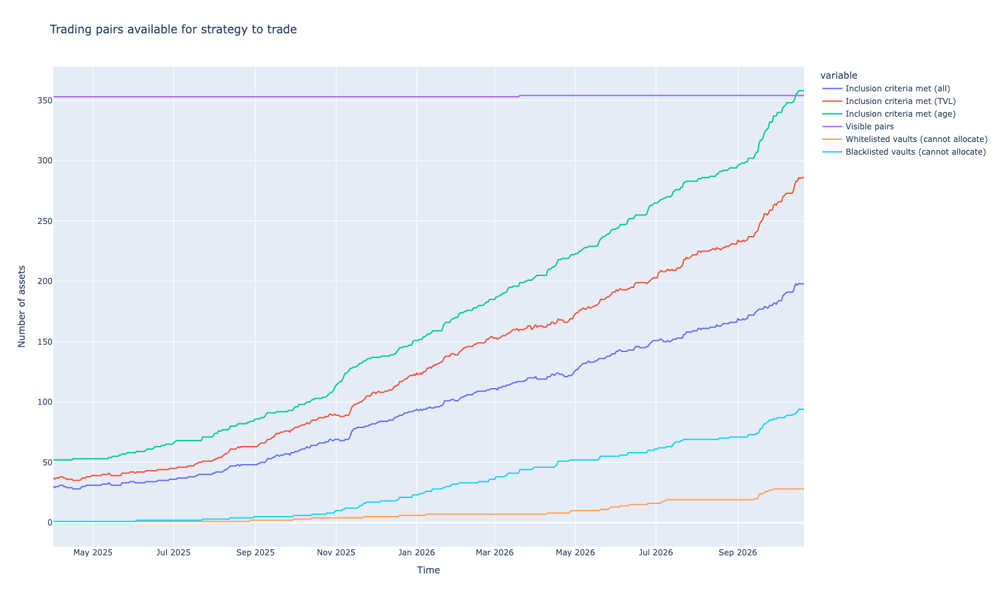

Head (5 rows)


,Inclusion criteria met (all),Inclusion criteria met (TVL),Inclusion criteria met (age),Visible pairs,Whitelisted vaults (cannot allocate),Blacklisted vaults (cannot allocate)
2024-06-01,5,8,13,346,0,0
2024-06-02,8,11,16,346,0,0
2024-06-03,8,11,16,346,0,0
2024-06-04,8,11,17,346,0,0
2024-06-05,8,11,17,346,0,0


Tail (5 rows)


,Inclusion criteria met (all),Inclusion criteria met (TVL),Inclusion criteria met (age),Visible pairs,Whitelisted vaults (cannot allocate),Blacklisted vaults (cannot allocate)
2026-10-17,198,286,358,354,28,94
2026-10-18,198,285,358,354,28,94
2026-10-19,198,286,358,354,28,94
2026-10-20,198,286,358,354,28,94
2026-10-21,198,286,358,354,28,94


In [10]:
indicator_data = calculate_and_load_indicators_inline(
    strategy_universe=strategy_universe,
    parameters=parameters,
    create_indicators=create_indicators,
    max_workers=1,
)

charts = create_charts(
    timestamp=None,
    parameters=parameters,
    strategy_universe=strategy_universe,
    execution_context=notebook_execution_context,
)
chart_renderer = ChartBacktestRenderingSetup(
    registry=charts,
    strategy_input_indicators=indicator_data,
    backtest_start_at=Parameters.backtest_start,
    backtest_end_at=Parameters.backtest_end,
)

fig, available_trading_pairs_df = chart_renderer.render(
    available_trading_pairs, with_dataframe=True
)
fig.show()
display_head_and_tail(available_trading_pairs_df, head_rows=5, tail_rows=5)


## Backtest

Run the backtest and check the headline outcome.


In [11]:
result = run_backtest_inline(
    client=client,
    universe=strategy_universe,
    decide_trades=decide_trades,
    create_indicators=create_indicators,
    parameters=Parameters,
    initial_deposit=Parameters.initial_cash,
    reserve_currency=ReserveCurrency.usdc,
    trade_routing=Parameters.routing,
    engine_version=trading_strategy_engine_version,
    max_workers=1,
    name=Parameters.id,
)

state = result.state
indicator_data = result.indicators
trades = list(state.portfolio.get_all_trades())
bridge_trades = [trade for trade in trades if trade.pair.is_cctp_bridge()]
vault_trades = [trade for trade in trades if trade.pair.kind.is_vault()]
equity_curve = calculate_equity_curve(state)
returns = calculate_returns(equity_curve)
final_equity = state.portfolio.get_total_equity()
total_return = final_equity / Parameters.initial_cash - 1
satellite_vault_trades = [
    trade
    for trade in vault_trades
    if trade.pair.chain_id != Parameters.primary_chain_id.value
]

summary_df = pd.DataFrame(
    [
        ("Initial cash USD", Parameters.initial_cash),
        ("Final equity USD", final_equity),
        ("Total return", total_return),
        ("Equity curve points", len(equity_curve)),
        ("All trades", len(trades)),
        ("Vault trades", len(vault_trades)),
        ("CCTP bridge trades", len(bridge_trades)),
        (
            "Successful CCTP bridge trades",
            sum(trade.is_success() for trade in bridge_trades),
        ),
        ("Satellite vault trades", len(satellite_vault_trades)),
    ],
    columns=["Metric", "Value"],
)

trade_chain_summary = pd.DataFrame(
    [
        (trade.pair.chain_id, trade.pair.kind.name, trade.get_value())
        for trade in trades
    ],
    columns=["Chain", "Kind", "Value USD"],
)
if not trade_chain_summary.empty:
    trade_chain_summary = (
        trade_chain_summary.groupby(["Chain", "Kind"], as_index=False)
        .agg(Trades=("Value USD", "size"), Total_value_usd=("Value USD", "sum"))
        .sort_values(["Chain", "Kind"])
    )

display(summary_df)
display(trade_chain_summary)

assert final_equity > 0, f"Expected positive portfolio equity, got {final_equity:,.2f}"
assert all(
    trade.is_success() for trade in bridge_trades
), "Expected all CCTP bridge trades to execute"

ignored_pair_ids = {
    pair.internal_id for pair in vault_pairs if pair.get_ignore_reason() is not None
}
ignored_vault_trades = [
    trade for trade in vault_trades if trade.pair.internal_id in ignored_pair_ids
]
assert (
    not ignored_vault_trades
), f"Expected no trades in ignored vaults, got {len(ignored_vault_trades)}"

# Keep the run state locally for checking results without repeating the simulation.
from pathlib import Path

artifact_directory = Path("_artifacts")
artifact_directory.mkdir(exist_ok=True)
state.write_json_file(artifact_directory / "backtest-state.json")
assert pd.Timestamp(equity_curve.index.max()).normalize() == pd.Timestamp(
    Parameters.backtest_end - datetime.timedelta(days=1)
), "Backtest did not reach the requested final day"


2026-10-21 13:10:17,462 tradeexecutor.backtest.backtest_execution          WARNING  Fixing token sell amount to be within the epsilon. Wallet balance: 3070.591968220636736199234042, sell order quantity: -3070.5919682206367724575102329254150390625, diff: 3.62582761909254150390625E-14


,Metric,Value
0,Initial cash USD,100000.000000
1,Final equity USD,117332.899612
2,Total return,0.173329
3,Equity curve points,568.000000
4,All trades,713.000000
5,Vault trades,540.000000
6,CCTP bridge trades,173.000000
7,Successful CCTP bridge trades,173.000000
8,Satellite vault trades,268.000000


,Chain,Kind,Trades,Total_value_usd
0,1,cctp_bridge,90,412712.283700
1,1,vault,150,635893.906235
2,143,cctp_bridge,8,33411.520229
3,143,vault,9,33411.520230
4,8453,cctp_bridge,45,204188.105453
5,8453,vault,75,267117.695035
6,42161,vault,272,681805.902482
7,43114,cctp_bridge,30,89918.743338
8,43114,vault,34,89918.743345


In [12]:
chart_renderer = ChartBacktestRenderingSetup(
    registry=charts,
    strategy_input_indicators=indicator_data,
    state=state,
    backtest_start_at=Parameters.backtest_start,
    backtest_end_at=Parameters.backtest_end,
)


## Ignored vaults and missing fee data

Vaults retained in the universe as data-only pairs (`ignore_reason="lacks_fee_data"`): excluded
from the inclusion criteria, never entered by the alpha model, listed with their missing fee
fields and Trading Strategy links.


In [13]:
ignored_vault_table = chart_renderer.render(ignored_vault_data)
display(ignored_vault_table)


Name,Chain,Address,Curator,Protocol,Missing fees,Link
Trust Wallet Fluid USDC,Arbitrum One,0x6db146db8dcf2f96948c3982f0770871246ae810,Trust Wallet,fluid,deposit fee,trust-wallet-fluid-usdc
Alpine Coinshift USDC,Ethereum,0x0985c88929a776a2e059615137a48ba5a473e25d,Alpine,upshift,"fee mode, management fee, performance fee",alpine-coinshift-usdc
Alpine USDC Flagship,Ethereum,0xd066649bcb7d8d3335fe29cad0aed6e17d5828b5,Alpine,upshift,"fee mode, management fee, performance fee",alpine-usdc-flagship
Multipli Upshift USDC,Ethereum,0x396a3f77ee1faf5a3c46e878ba7b7a2dcbe55517,August Digital,upshift,"fee mode, management fee, performance fee",multipli-upshift-usdc
Resolv USR Yield Maxi,Ethereum,0xda89af5bf2eb0b225d787abfa9095610f2e79e7d,M1 Capital,upshift,"fee mode, management fee, performance fee",resolv-usr-yield-maxi
Sylva Concentrated Liquidity,Ethereum,0xc428439fb7b1efe56360eb837ca98f551fdd9b26,Sylva.money,upshift,"fee mode, management fee, performance fee",sylva-concentrated-liquidity
Upshift AZT,Ethereum,0x69fc3f84fd837217377d9dae0212068ceb65818e,Upshift,upshift,"fee mode, management fee, performance fee",upshift-azt
Upshift Core USDC,Ethereum,0xe9b725010a9e419412ed67d0fa5f3a5f40159d32,August Digital,upshift,"fee mode, management fee, performance fee",upshift-core-usdc
Upshift Gamma USDC Vault,Ethereum,0x998d7b14c123c1982404562b68eddb057b0477cb,Gamma Research,upshift,"fee mode, management fee, performance fee",upshift-gamma-usdc-vault
Upshift USDC,Ethereum,0x80e1048ede66ec4c364b4f22c8768fc657ff6a42,August Digital,upshift,"fee mode, management fee, performance fee",upshift-usdc


## Vaults retained only for diagnostics

Whitelisted vaults require depositor allow-list approval. Producer-blacklisted vaults can enter a source list only accidentally; the default universe guard makes both data-only and lists them here.


In [14]:
whitelisted_vault_table = render_whitelisted_vaults(strategy_universe)
display(whitelisted_vault_table)

blacklisted_vault_table = render_blacklisted_vaults(strategy_universe)
display(blacklisted_vault_table)


Name,Protocol,Chain,Address
USDC Lending Optimizer Tezos,ipor-fusion,Base,0x585aa9eb2c8d51ab5f436b27b11bb23350570b3f
AltaETF,lagoon-finance,Ethereum,0x3be67ba2d3fec744d1d2b5d564c83f57372578e4
Balanced Vault,lagoon-finance,Ethereum,0xa5ae405242f42c47996a0c6857ff10a77f9bdee6
Block4Block,lagoon-finance,Ethereum,0x9fdbaaa76194d56e49cade12c1f216f47d2b865e
Boosted Vault,lagoon-finance,Ethereum,0x9e0db8f43bb91e2148b0db920e21370525cf3aab
Der USDC,lagoon-finance,Ethereum,0xf10801bcc3deaf467fb8b3dbb7430111822e6dab
Der base USDC,lagoon-finance,Ethereum,0xba6cfe8a9d199cd7f3e50114c4e4ec66f2d52c87
Ensuro IPOR Vault,ipor-fusion,Ethereum,0xdcd8cb1e2ba62faef6c4c258508d7d959e5f3408
Evergreen.001,lagoon-finance,Ethereum,0xb1e65871a38a483eee9436791ac016ddce3ae4ad
Muchacho USDC,lagoon-finance,Ethereum,0xef39d77c7fb6224ac974c5fa4e3151a6c6ce9594


Name,Protocol,Chain,Address,Risk
Arbitrum USDC Mix Yield Token,morpho,Arbitrum One,0xeba62b842081cef5a8184318dc5c4e4aaca9f651,Blacklisted
Blend USDC,morpho,Arbitrum One,0x9ce8a73296704d4689586347ef6e2087c2128f45,Blacklisted
Blend USDC Reserve,morpho,Arbitrum One,0xa47c5203d22ae173788a9d9be0f2beecc97f4df9,Blacklisted
Dynamic Alpha Sentiment 2X,lagoon-finance,Arbitrum One,0x57587aee66d70d99024b02919901cfe552f5a0d4,Blacklisted
Steakhouse High Yield Turbo,morpho,Arbitrum One,0xbeefff13dd098de415e07f033dae65205b31a894,Blacklisted
TID Capital Perp Market Maker,lagoon-finance,Arbitrum One,0x7f14715bc12214f1ff26a6863334e7c8b644f4f7,Blacklisted
USDC Yield,lagoon-finance,Arbitrum One,0x307139c61d3f884def18c8dc1676eb88e1ed7839,Blacklisted
VaultMorpho,morpho,Arbitrum One,0x46ce9aa8167fa3e154395c25d19db25ddfcfeab4,Blacklisted
syrupUSDC/USDC Morpho Looper,morpho,Arbitrum One,0xbcf08997c34183d1b7b0f99e13aceacfba88e453,Blacklisted
Avvio Base USDC,morpho,Base,0xef1e25cbb1672c180d0362e6c1afe531154b099f,Blacklisted


## Equity curve

Total portfolio equity through the backtest.


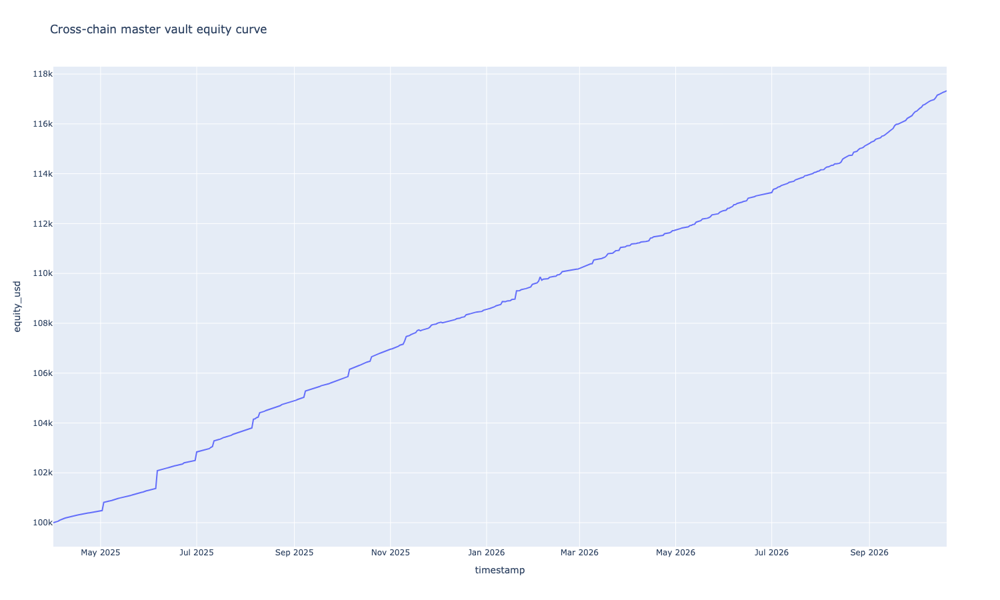

In [15]:
equity_df = equity_curve.rename("equity_usd").reset_index()
equity_df.columns = ["timestamp", "equity_usd"]
fig = px.line(
    equity_df,
    x="timestamp",
    y="equity_usd",
    title="Cross-chain master vault equity curve",
)
fig.show()


## Performance metrics

Standard performance metrics against BTC and ETH benchmarks.


In [16]:
performance_metrics_df = chart_renderer.render(performance_metrics)
display(performance_metrics_df)


,Strategy,BTC,ETH
Start Period,2025-04-01,2025-04-01,2025-04-01
End Period,2026-10-20,2026-10-20,2026-10-20
Risk-Free Rate,0.0%,0.0%,0.0%
Time in Market,100.0%,100.0%,100.0%
Cumulative Return,17.33%,-2.91%,28.36%
CAGR﹪,10.84%,-1.88%,17.44%
Sharpe,11.33,0.16,0.57
Prob. Sharpe Ratio,100.0%,58.07%,76.38%
Smart Sharpe,10.85,0.16,0.55
Sortino,101.45,0.24,0.89


## Asset weight chart

How portfolio allocation moved across vault assets during the backtest.


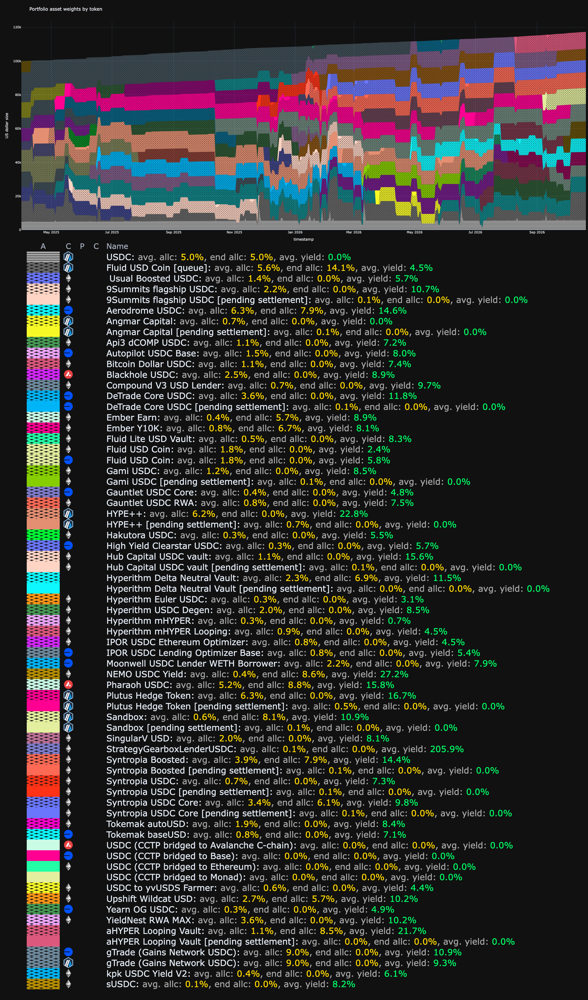

Vault name,First settle,Last settle,Settlements observed,Average estimation used,No-data settlement delay,Simulated no-data settlements
1212.Alpha,NaT,NaT,0,2 days,4 days,0
1212.Stable,NaT,NaT,0,2 days,4 days,0
722 Capital USDC,NaT,NaT,0,2 days,4 days,0
9Summits Institutional Credit USDC,NaT,NaT,0,2 days,4 days,0
9Summits flagship USDC,NaT,NaT,0,2 days,4 days,3
AltaETF,NaT,NaT,0,2 days,4 days,0
Ammalgam USDC Vault,NaT,NaT,0,2 days,4 days,0
Angmar Capital,NaT,NaT,0,2 days,4 days,2
Autonomous Liquidity USD,NaT,NaT,0,2 days,4 days,0
Balanced Vault,NaT,NaT,0,2 days,4 days,0


In [17]:
token_weights_fig = chart_renderer.render(equity_curve_by_asset_with_legend)
token_weights_fig.show(
    width=token_weights_fig.layout.width, height=token_weights_fig.layout.height
)

settlement_observations_df = chart_renderer.render(vault_settlement_observations)
display(settlement_observations_df.style.hide(axis="index"))


## Asset weights by liquidity state

How capital moved between ordinary deployed positions, raw cash, the free queue venue, deposits waiting for a target vault's deposit window, and deposits already in asynchronous settlement. The bands reconcile to total portfolio equity; patterned bands identify capital that is earmarked rather than freely allocatable.


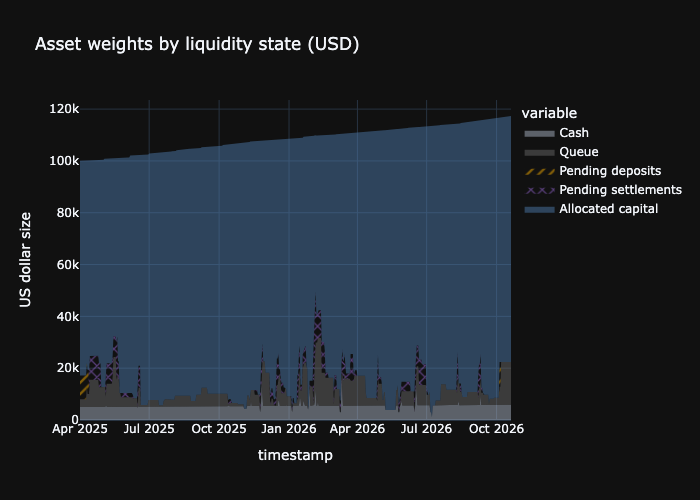

In [18]:
liquidity_state_weights_fig, liquidity_state_weights_df = chart_renderer.render(
    equity_curve_by_liquidity_state
)
liquidity_state_weights_fig.show(
    width=liquidity_state_weights_fig.layout.width,
    height=liquidity_state_weights_fig.layout.height,
)


## Chain weight chart

USD allocation per chain over time, with the queue venue as its own band.


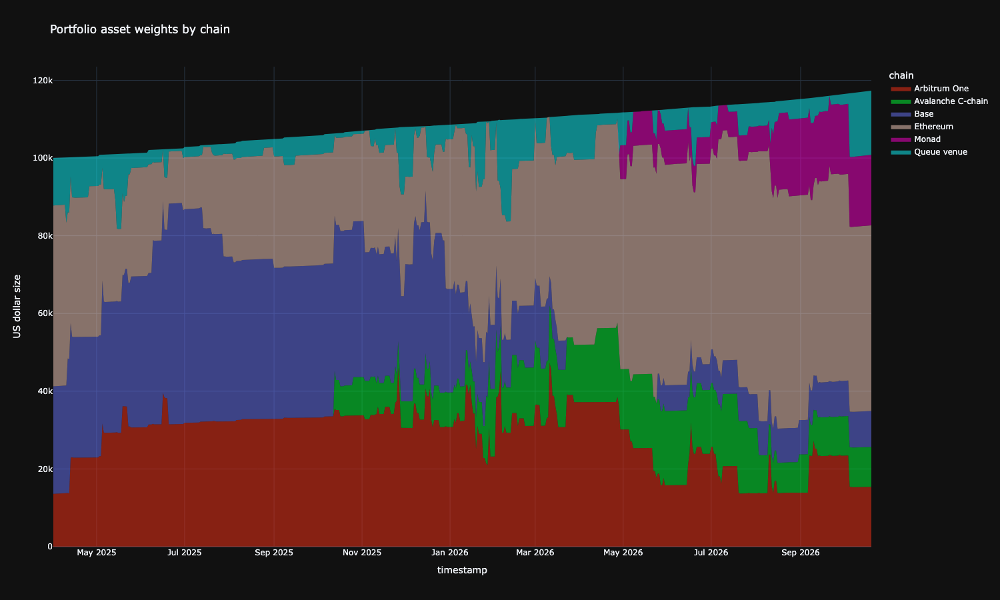

Head (10 rows)


chain,Arbitrum One,Avalanche C-chain,Base,Ethereum,Monad,Queue venue
timestamp,,,,,,
2025-04-01,13610.829191,0.0,27651.676836,46536.593973,0.0,12200.900000
2025-04-02,13612.722529,0.0,27658.536479,46543.302559,0.0,12202.848357
2025-04-03,13615.459797,0.0,27666.021962,46546.345067,0.0,12204.658369
2025-04-04,13617.118303,0.0,27672.346041,46558.461829,0.0,12206.779657
2025-04-05,13619.451953,0.0,27679.271927,46588.202305,0.0,12208.693428
2025-04-06,13626.734494,0.0,27685.158769,46612.788043,0.0,12204.384485
2025-04-07,13632.113630,0.0,27690.662463,46616.518459,0.0,12206.470084
2025-04-08,13645.821986,0.0,27700.160976,46620.174517,0.0,12208.382844
2025-04-09,13650.474608,0.0,27707.822529,46624.313894,0.0,12210.180376


Tail (10 rows)


chain,Arbitrum One,Avalanche C-chain,Base,Ethereum,Monad,Queue venue
timestamp,,,,,,
2026-10-11,15321.950770,10238.259297,9179.199347,47637.111627,18055.286202,16523.790377
2026-10-12,15321.950770,10245.638315,9185.403426,47636.558206,18059.956162,16526.895531
2026-10-13,15359.564021,10251.254126,9192.126407,47656.218719,18065.622416,16522.121469
2026-10-14,15364.837253,10259.073945,9197.815525,47741.381526,18069.704949,16519.558609
2026-10-15,15367.449612,10262.556278,9203.502211,47749.204459,18073.598377,16522.122443
2026-10-16,15372.387061,10266.585204,9211.635102,47756.342651,18081.171362,16525.472909
2026-10-17,15372.387061,10271.248884,9218.397608,47775.868300,18086.124814,16528.109580
2026-10-18,15378.428862,10278.486845,9223.469825,47775.314879,18092.234854,16525.272571
2026-10-19,15381.741441,10281.166919,9230.247123,47774.761458,18098.057974,16527.937403


In [19]:
chain_weights_fig, chain_weights_df = chart_renderer.render(equity_curve_by_chain)
chain_weights_fig.update_layout(title="Portfolio asset weights by chain")
chain_weights_fig.show()
display_head_and_tail(chain_weights_df, head_rows=10, tail_rows=10)


## Pending settlements chart

Capital pending in async vault settlements and the phase-aware trigger queue.


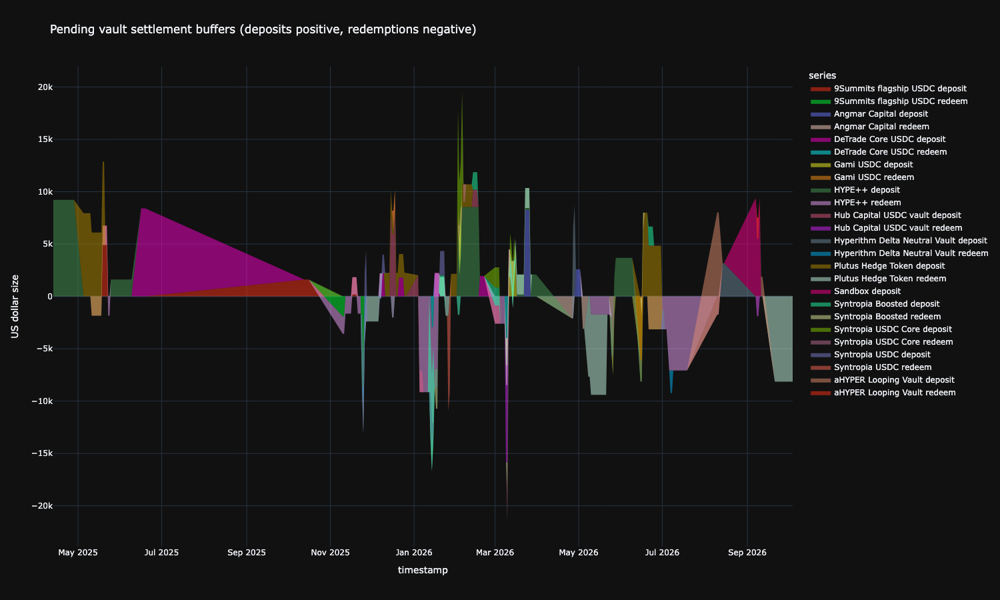

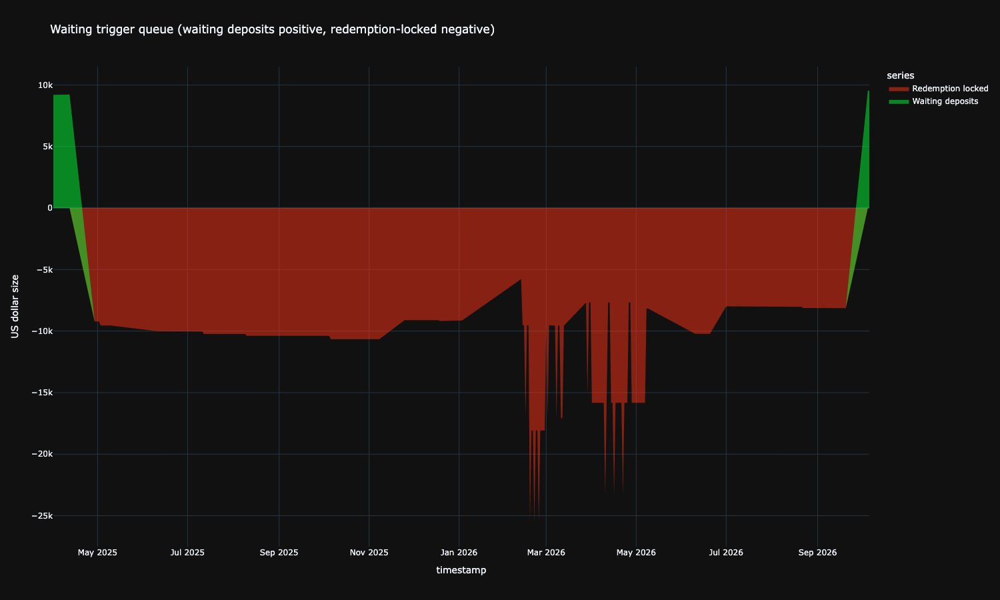

Head (5 rows)


series,Redemption locked,Waiting deposits
timestamp,,
2025-04-01,0.0,9199.900000
2025-04-02,0.0,9201.553943
2025-04-03,0.0,9202.986094
2025-04-04,0.0,9205.097054
2025-04-05,0.0,9208.983863


Tail (5 rows)


series,Redemption locked,Waiting deposits
timestamp,,
2026-09-18,-8143.031212,0.000000
2026-09-19,-8143.031212,0.000000
2026-09-20,-8143.031212,0.000000
2026-10-05,0.000000,9531.713695
2026-10-06,0.000000,9533.153798


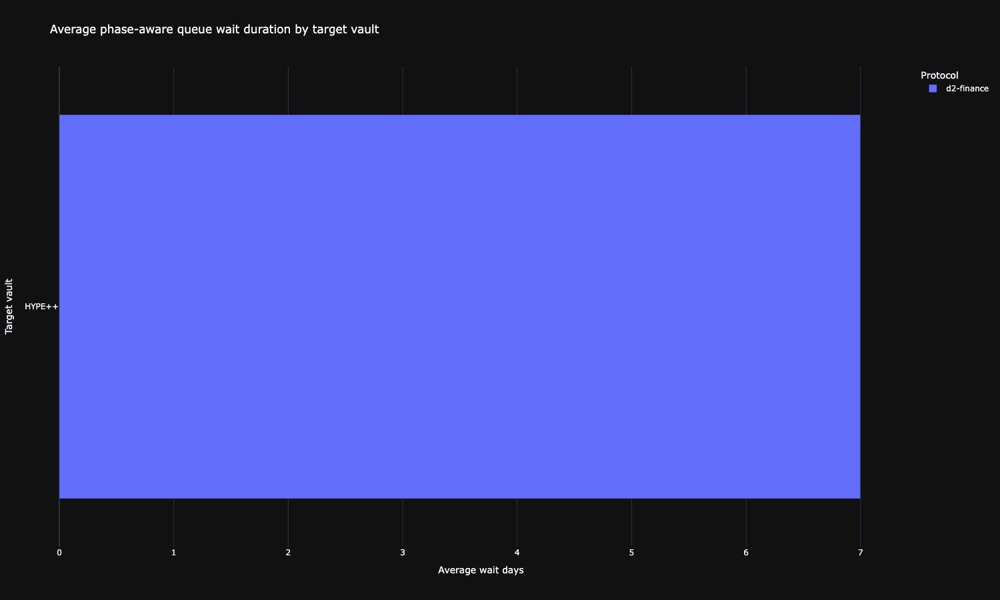

,Vault id,Vault,Ticker,Protocol,Chain,Episodes,Promoted,Closed,Open,Average wait days,Median wait days,Max wait days,Average start USD,Max queued USD,USD days
0,272519172,HYPE++,HYPE++-USDC,d2-finance,42161,2,1,1,0,7.0,7.0,12.0,9365.806848,9533.153798,129609.666101


,Vault id,Vault,Ticker,Protocol,Chain,Episodes,Promoted,Closed,Open,Average wait days,Median wait days,Max wait days,Average start USD,Max queued USD,USD days
0,272519172,HYPE++,HYPE++-USDC,d2-finance,42161,2,1,1,0,7.0,7.0,12.0,9365.806848,9533.153798,129609.666101


,Component,USD
0,Fluid queue venue,16531.155586
1,Waiting-deposit earmarks,0.000000
2,Free queue liquidity,16531.155586
3,Raw USDC reserve,5863.660392
4,Pending async deposit claims,0.000000


""


""


,Kind,USD,Cycle,Timestamp
0,park,9199.900000,1,2025-04-01T00:00:00
1,park,9201.553943,2,2025-04-02T00:00:00
2,park,9202.986094,3,2025-04-03T00:00:00
3,park,9205.097054,4,2025-04-04T00:00:00
4,park,9208.983863,5,2025-04-05T00:00:00
5,park,9212.161250,6,2025-04-06T00:00:00
6,park,9213.747640,7,2025-04-07T00:00:00
7,park,9216.481331,8,2025-04-08T00:00:00
8,park,9218.215184,9,2025-04-09T00:00:00
9,park,9219.782110,10,2025-04-10T00:00:00


... (2 outputs left out)

,Metric,Value
0,Final cycle,2026-10-20 00:00:00
1,Total equity USD,117332.9
2,Cash USD,5863.66
3,Cash % of equity,0.049975
4,Redeemable capital USD,NaN
5,Pending redemptions USD,NaN
6,Investable equity USD,108465.25
7,Accepted investable equity USD,108465.25
8,Accepted / investable %,1.0
9,Allocated to signals USD,108465.25


,Signal,Asked size,Accepted size,Value adjust USD,Weights (raw),Weights (norm/cap),Old weight,Flipping,TVL,Pending deposit USD,Pending redemption USD,Parked USD,Waiting deposit USD,Deposit block reason,Deposit block message,Max deposit,Waiting redemption USD,Flags
Pair,,,,,,,,,,,,,,,,,,
eY10K-USDC,0.912162,6148.407089,6148.407089,0.0,0.055128,0.056685,0.082430,no flip,18019164,-,-,-,-,-,-,-,-,max_adjust_too_small
wildUSD-USDC,0.918919,6720.351935,6720.351935,0.0,0.060256,0.061959,0.070381,no flip,803528,-,-,-,-,-,-,-,-,max_adjust_too_small
eEARN-USDC,0.925676,7292.296780,7292.296780,0.0,0.065385,0.067232,0.070632,no flip,3672017,-,-,-,-,-,-,-,-,max_adjust_too_small
synUSD-USDC,0.932432,7864.241626,7864.241626,0.0,0.070513,0.072505,0.075686,no flip,1088593,-,-,-,-,-,-,-,-,max_adjust_too_small
USDACM-USDC,0.952703,8436.186471,8436.186471,0.0,0.075641,0.077778,0.100253,no flip,448796,-,-,-,-,-,-,-,-,max_adjust_too_small
aHYPER-USDC,0.959459,9008.131317,9008.131317,0.0,0.080769,0.083051,0.085024,no flip,76127933,-,-,-,-,-,-,-,-,max_adjust_too_small
HYPE++-USDC,0.966216,9580.076162,9580.076162,0.0,0.085897,0.088324,0.000000,none -> spot,8662164,-,-,-,-,-,-,-,-,max_adjust_too_small
synUSDx-USDC,0.972973,10152.021008,10152.021008,0.0,0.091026,0.093597,0.097834,no flip,312560,-,-,-,-,-,-,-,-,max_adjust_too_small
aHYPERLOOP-USDC,0.979730,10723.965853,10723.965853,0.0,0.096154,0.098870,0.105664,no flip,6770795,-,-,-,-,-,-,-,-,max_adjust_too_small


,Cycle timestamp,Vault,Pair,Address,Blocked buy USD,Reason code,Reason detail,Max deposit USD
26,1789948800,Hyperithm Delta Neutral Vault,aHYPER-USDC,0x7cd231120a60f500887444a9baf5e1bd753a5e59,2032.177235,vault_max_deposit_zero,Historical vault deposit capacity was zero,0.0


,Vault,Address,Reason code,Reason detail,Max deposit USD,First_blocked_cycle,Last_blocked_cycle,Blocked_cycles,Total_blocked_buy_usd
0,Hyperithm Delta Neutral Vault,0x7cd231120a60f500887444a9baf5e1bd753a5e59,vault_max_deposit_zero,Historical vault deposit capacity was zero,0.0,1785110400,1789948800,27,67031.762541


In [20]:
settlement_fig, settlement_df = chart_renderer.render(pending_vault_settlements)
settlement_fig.show()

trigger_fig, trigger_df = chart_renderer.render(pending_trigger_queue)
trigger_fig.show()
if not trigger_df.empty:
    display_head_and_tail(trigger_df, head_rows=5, tail_rows=5)
queue_duration_fig, queue_duration_df = chart_renderer.render(
    phase_aware_queue_duration
)
queue_duration_fig.show()
if not queue_duration_df.empty:
    display(queue_duration_df)

queue_duration_summary_df = chart_renderer.render(phase_aware_queue_duration_summary)
if not queue_duration_summary_df.empty:
    display(queue_duration_summary_df)

# End-of-backtest queue reconciliation: distinguish target earmarks from free sweep liquidity.
from tradeexecutor.strategy.phase_aware import (
    iter_all_events,
    read_open_park_events,
    read_open_redeem_block_events,
)

open_parks = read_open_park_events(state.other_data)
open_redemption_locks = read_open_redeem_block_events(state.other_data)
end_queue_usd = float(chain_weights_df.iloc[-1]["Queue venue"])
waiting_deposits_usd = sum(event.usd for event in open_parks.values())
display(
    pd.DataFrame(
        [
            ("Fluid queue venue", end_queue_usd),
            ("Waiting-deposit earmarks", waiting_deposits_usd),
            ("Free queue liquidity", end_queue_usd - waiting_deposits_usd),
            ("Raw USDC reserve", float(state.portfolio.get_cash())),
            (
                "Pending async deposit claims",
                state.portfolio.get_vault_settlement_pending_value(),
            ),
        ],
        columns=["Component", "USD"],
    )
)


def resolve_queue_event(event):
    pair = strategy_universe.get_pair_by_id(event.vault_internal_id)
    return {
        "Vault": pair.get_vault_name() or pair.get_ticker(),
        "Chain": pair.chain_id,
        "USD": event.usd,
        "Cycle": event.cycle,
        "Event timestamp": event.timestamp,
    }


display(pd.DataFrame([resolve_queue_event(event) for event in open_parks.values()]))
display(
    pd.DataFrame(
        [resolve_queue_event(event) for event in open_redemption_locks.values()]
    )
)

# HYPE++'s full phase-aware event history proves whether its redemption lock cleared during
# the 3-4 August synthetic window and, if so, whether a later closed-window cycle re-blocked it.
hype_pair = strategy_universe.get_pair_by_smart_contract(WINDOW_GATED_VAULTS[0][1])
hype_events_df = pd.DataFrame(
    [
        {
            "Kind": event.kind,
            "USD": event.usd,
            "Cycle": event.cycle,
            "Timestamp": event.timestamp,
        }
        for event in iter_all_events(state.other_data)
        if event.vault_internal_id == hype_pair.internal_id
    ]
)
display(hype_events_df)

# Pending settlement deposits are outside the Fluid queue. List their vaults separately so
# operational settlement latency cannot be mistaken for unallocated queue liquidity.
pending_settlement_rows = []
for position in state.portfolio.get_all_positions(pending=True):
    pending_value = position.get_vault_settlement_pending_value()
    if pending_value <= 0:
        continue
    pending_trades = [
        trade
        for trade in position.trades.values()
        if trade.is_vault_settlement_in_flight() and trade.is_buy()
    ]
    pending_settlement_rows.append(
        {
            "Vault": position.pair.get_vault_name() or position.pair.get_ticker(),
            "Protocol": position.pair.exchange_name,
            "Chain": position.pair.chain_id,
            "Pending deposit USD": pending_value,
            "Position id": position.position_id,
            "Request trade ids": ", ".join(
                str(trade.trade_id) for trade in pending_trades
            ),
            "Request opened": ", ".join(
                str(trade.opened_at) for trade in pending_trades
            ),
        }
    )

display(pd.DataFrame(pending_settlement_rows))

# A redemption lock is an availability diagnostic, not a withdrawal order. Show the HYPE++
# ledger around the final window so any actual deposit or redemption is explicit.
hype_window_start = datetime.datetime(2026, 8, 25)
hype_window_end = datetime.datetime(2026, 9, 1)
hype_window_trades_df = pd.DataFrame(
    [
        {
            "Trade id": trade.trade_id,
            "Opened": trade.opened_at,
            "Executed": trade.executed_at,
            "Side": "Buy / deposit" if trade.is_buy() else "Sell / redeem",
            "Status": trade.get_status().value,
            "Value USD": trade.get_value(),
        }
        for trade in trades
        if trade.pair.internal_id == hype_pair.internal_id
        and trade.opened_at is not None
        and hype_window_start <= trade.opened_at < hype_window_end
    ]
)
display(hype_window_trades_df)

# Final-cycle allocation audit: expose whether the directional allocator accepted the
# deployable capital and which final-cycle signals were constrained or skipped.
final_cycle_snapshot_df = chart_renderer.render(latest_cycle_snapshot)
display(final_cycle_snapshot_df)
final_alpha_model_df = chart_renderer.render(alpha_model_diagnostics)
display(final_alpha_model_df)

# Deposit-gate audit: `cannot_deposit` is a trade-generation result, not an allocator
# decision. Persisted per-cycle results identify whether the protocol was closed, the
# owner cap was zero, or an asynchronous request manager rejected the request.
deposit_block_rows = []
for cycle_timestamp, calculations in state.visualisation.calculations.items():
    for event in calculations.get("missed_vault_events", []):
        if event.get("event_type") != "deposit":
            continue
        deposit_block_rows.append(
            {
                "Cycle timestamp": cycle_timestamp,
                "Vault": event.get("vault_name"),
                "Pair": event.get("pair_ticker"),
                "Address": event.get("vault_address"),
                "Blocked buy USD": event.get("missed_usd", 0.0),
                "Reason code": event.get("reason_code", "legacy/unknown"),
                "Reason detail": event.get(
                    "reason_message", "No structured diagnostic recorded"
                ),
                "Max deposit USD": event.get("max_deposit"),
            }
        )

deposit_blocks_df = pd.DataFrame(deposit_block_rows)
if deposit_blocks_df.empty:
    display(
        pd.DataFrame(
            columns=[
                "Cycle timestamp",
                "Vault",
                "Pair",
                "Address",
                "Blocked buy USD",
                "Reason code",
                "Reason detail",
                "Max deposit USD",
            ]
        )
    )
else:
    deposit_blocks_df = deposit_blocks_df.sort_values(
        ["Cycle timestamp", "Blocked buy USD"], ascending=[False, False]
    )
    latest_deposit_blocks_df = deposit_blocks_df[
        deposit_blocks_df["Cycle timestamp"]
        == deposit_blocks_df["Cycle timestamp"].max()
    ]
    display(latest_deposit_blocks_df)
    display(
        deposit_blocks_df.groupby(
            ["Vault", "Address", "Reason code", "Reason detail", "Max deposit USD"],
            dropna=False,
            as_index=False,
        )
        .agg(
            First_blocked_cycle=("Cycle timestamp", "min"),
            Last_blocked_cycle=("Cycle timestamp", "max"),
            Blocked_cycles=("Cycle timestamp", "size"),
            Total_blocked_buy_usd=("Blocked buy USD", "sum"),
        )
        .sort_values("Total_blocked_buy_usd", ascending=False)
    )


In [21]:
from eth_defi.erc_4626.core import ERC4626Feature

# Protocol settlement and stale-data utilisation audit. These rows come from the realised
# backtest trade ledger, so they expose the effective flow rather than only configured metadata.
settlement_features = {
    ERC4626Feature.lagoon_like,
    ERC4626Feature.d2_like,
    ERC4626Feature.plutus_like,
}
stale_deposit_features = {
    ERC4626Feature.lagoon_like,
    ERC4626Feature.morpho_v2_like,
    ERC4626Feature.yearn_v3_like,
}

protocol_rows = []
stale_rows = []
for pair in vault_pairs:
    features = pair.get_vault_features() or set()
    pair_trades = [
        trade for trade in vault_trades if trade.pair.internal_id == pair.internal_id
    ]
    if features & settlement_features:
        for trade in pair_trades:
            estimated_at = trade.other_data.get("vault_settlement_estimated_at")
            estimated_delay_days = None
            if estimated_at and trade.opened_at:
                estimated_delay_days = (
                    datetime.datetime.fromisoformat(estimated_at) - trade.opened_at
                ).total_seconds() / 86_400
            protocol_rows.append(
                {
                    "Vault": pair.get_vault_name() or pair.get_ticker(),
                    "Protocol": pair.get_vault_protocol(),
                    "Features": ", ".join(
                        sorted(
                            feature.value for feature in features & settlement_features
                        )
                    ),
                    "Side": "deposit" if trade.is_buy() else "redeem",
                    "Opened": trade.opened_at,
                    "Status": trade.get_status().value,
                    "Metadata settlement days": (
                        pair.get_vault_estimated_settlement().total_seconds() / 86_400
                        if pair.get_vault_estimated_settlement()
                        else None
                    ),
                    "Applied settlement days": estimated_delay_days,
                    "Historical settlement required": bool(
                        trade.other_data.get(
                            "vault_settlement_historical_event_required"
                        )
                    ),
                    "Historical settlement event": trade.other_data.get(
                        "vault_settlement_historical_event_at"
                    ),
                    "Last observed historical event": trade.other_data.get(
                        "vault_settlement_last_historical_event_at"
                    ),
                    "Value USD": trade.get_value(),
                }
            )
    if features & stale_deposit_features:
        stale_rows.append(
            {
                "Vault": pair.get_vault_name() or pair.get_ticker(),
                "Protocol": pair.get_vault_protocol(),
                "Features": ", ".join(
                    sorted(
                        feature.value for feature in features & stale_deposit_features
                    )
                ),
                "Deposit trades": sum(trade.is_buy() for trade in pair_trades),
                "Successful deposits": sum(
                    trade.is_buy() and trade.is_success() for trade in pair_trades
                ),
                "Pending deposits": sum(
                    trade.is_buy() and trade.is_vault_settlement_in_flight()
                    for trade in pair_trades
                ),
                "Deposit value USD": sum(
                    trade.get_value() for trade in pair_trades if trade.is_buy()
                ),
            }
        )

protocol_settlement_audit_df = pd.DataFrame(protocol_rows).sort_values(
    ["Vault", "Opened"]
)
stale_vault_utilisation_df = pd.DataFrame(stale_rows).sort_values(
    ["Successful deposits", "Deposit trades"], ascending=False
)
protocol_settlement_summary_df = (
    protocol_settlement_audit_df.groupby(
        [
            "Vault",
            "Protocol",
            "Features",
            "Side",
            "Status",
            "Metadata settlement days",
            "Applied settlement days",
            "Historical settlement required",
            "Historical settlement event",
            "Last observed historical event",
        ],
        dropna=False,
        as_index=False,
    )
    .agg(
        Trades=("Opened", "size"),
        First_trade=("Opened", "min"),
        Last_trade=("Opened", "max"),
        Total_value_USD=("Value USD", "sum"),
    )
    .sort_values(["Vault", "Side", "Status"])
)
settlement_evidence_rows = []
for pair in vault_pairs:
    features = pair.get_vault_features() or set()
    if not features & settlement_features:
        continue
    pair_state = strategy_universe.vault_state
    pair_events = (
        pair_state[
            (pair_state["pair_id"] == pair.internal_id)
            & pair_state.get(
                "vault_settlement_at",
                pd.Series(index=pair_state.index, dtype="datetime64[ns]"),
            ).notna()
        ]
        if pair_state is not None and "vault_settlement_at" in pair_state.columns
        else pd.DataFrame()
    )
    settlement_evidence_rows.append(
        {
            "Vault": pair.get_vault_name() or pair.get_ticker(),
            "Historical events": len(pair_events),
            "First historical event": (
                pair_events["vault_settlement_at"].min() if len(pair_events) else None
            ),
            "Last historical event": (
                pair_events["vault_settlement_at"].max() if len(pair_events) else None
            ),
        }
    )
settlement_evidence_df = pd.DataFrame(settlement_evidence_rows).sort_values("Vault")
display(settlement_evidence_df)
display(protocol_settlement_summary_df)
display(stale_vault_utilisation_df[stale_vault_utilisation_df["Deposit trades"] > 0])


# Portfolio-stability experiment audit: reconcile vault PnL, turnover and holding periods.
position_rows = []
for position in state.portfolio.get_all_positions(pending=True):
    if not position.pair.is_vault():
        continue
    terminal_at = position.closed_at or (
        Parameters.backtest_end - datetime.timedelta(days=1)
    )
    position_trades = list(position.trades.values())
    position_rows.append(
        {
            "Vault": position.pair.get_vault_name() or position.pair.get_ticker(),
            "Protocol": position.pair.get_vault_protocol(),
            "Chain": int(position.pair.chain_id),
            "Positions": 1,
            "Trades": len(position_trades),
            "Turnover USD": sum(
                trade.get_value()
                for trade in position_trades
                if trade.is_success() or trade.is_pending()
            ),
            "Profit USD": position.get_total_profit_usd(),
            "Holding days": (terminal_at - position.opened_at).total_seconds() / 86_400,
        }
    )

position_audit_df = pd.DataFrame(position_rows)
vault_contribution_df = position_audit_df.groupby(
    ["Vault", "Protocol", "Chain"], as_index=False
).agg(
    Positions=("Positions", "sum"),
    Trades=("Trades", "sum"),
    Turnover_USD=("Turnover USD", "sum"),
    Profit_USD=("Profit USD", "sum"),
    Average_holding_days=("Holding days", "mean"),
)
vault_contribution_df["Profit_bps_per_turnover"] = (
    vault_contribution_df["Profit_USD"]
    / vault_contribution_df["Turnover_USD"].replace(0, np.nan)
    * 10_000
)

membership_changes = 0
previous_members = None
for cycle in sorted(state.other_data.data, key=int):
    members = state.other_data.data[cycle].get(STABLE_MEMBERS_KEY)
    if members is None:
        continue
    current_members = tuple(members)
    if previous_members is not None and current_members != previous_members:
        membership_changes += 1
    previous_members = current_members

# NB47 figures use its shorter window and original source list.
comparison_df = pd.DataFrame(
    [
        ("Final equity USD", 115_241.488065, final_equity),
        (
            "CAGR",
            0.1053393,
            (final_equity / Parameters.initial_cash)
            ** (
                365
                / (
                    (
                        Parameters.backtest_end
                        - datetime.timedelta(days=1)
                        - Parameters.backtest_start
                    ).days
                )
            )
            - 1,
        ),
        ("All trades", 844, len(trades)),
        ("Vault trades", 635, len(vault_trades)),
        ("CCTP bridge trades", 209, len(bridge_trades)),
        ("Vault turnover USD", 2_108_339.0, position_audit_df["Turnover USD"].sum()),
        (
            "Median position holding days",
            42.0,
            position_audit_df["Holding days"].median(),
        ),
    ],
    columns=["Metric", "NB47 through 2026-08-31", "xchain3 through 2026-10-20"],
)
comparison_df["Change"] = (
    comparison_df["xchain3 through 2026-10-20"]
    - comparison_df["NB47 through 2026-08-31"]
)

cap_diagnostics_rows = []
for unix_timestamp, messages in state.visualisation.messages.items():
    message = "\n".join(messages)
    member_match = re.search(r"Allocatable members: (\d+)", message)
    cap_match = re.search(r"Effective concentration cap: ([0-9.]+)%", message)
    if member_match is None or cap_match is None:
        continue
    cap_diagnostics_rows.append(
        {
            "Date": pd.Timestamp(unix_timestamp, unit="s"),
            "Allocatable members": int(member_match.group(1)),
            "Effective cap": float(cap_match.group(1)) / 100,
        }
    )
cap_diagnostics_df = pd.DataFrame(cap_diagnostics_rows)
cap_activation_summary_df = pd.DataFrame(
    [
        ("Cycles with a cap diagnostic", len(cap_diagnostics_df)),
        (
            "Cycles above base concentration cap",
            int(
                (
                    cap_diagnostics_df["Effective cap"]
                    > Parameters.max_concentration_pct
                ).sum()
            ),
        ),
        (
            "Minimum allocatable members",
            cap_diagnostics_df["Allocatable members"].min(),
        ),
        ("Maximum effective cap", cap_diagnostics_df["Effective cap"].max()),
    ],
    columns=["Metric", "Value"],
)

daily_jump_df = (
    pd.concat([returns.nlargest(5), returns.nsmallest(5)])
    .sort_values(ascending=False)
    .rename("Daily return")
    .reset_index()
)
experiment_diagnostics_df = pd.DataFrame(
    [
        ("Distinct vaults traded", len(vault_contribution_df)),
        ("Vault positions", len(position_audit_df)),
        ("Membership changes", membership_changes),
        (
            "Positions held <= 2 days",
            int((position_audit_df["Holding days"] <= 2).sum()),
        ),
        (
            "Positions held <= 7 days",
            int((position_audit_df["Holding days"] <= 7).sum()),
        ),
        ("Negative-PnL vaults", int((vault_contribution_df["Profit_USD"] < 0).sum())),
        (
            "Total negative vault PnL USD",
            vault_contribution_df.loc[
                vault_contribution_df["Profit_USD"] < 0, "Profit_USD"
            ].sum(),
        ),
    ],
    columns=["Metric", "Value"],
)

display(comparison_df)
display(experiment_diagnostics_df)
display(cap_activation_summary_df)
display(
    cap_diagnostics_df[
        cap_diagnostics_df["Effective cap"] > Parameters.max_concentration_pct
    ]
)
display(vault_contribution_df.sort_values("Profit_USD", ascending=False).head(15))
display(vault_contribution_df.sort_values("Profit_USD").head(15))
display(daily_jump_df)

valuation_change_rows = []
for position in state.portfolio.get_all_positions(pending=True):
    if not position.pair.is_vault():
        continue
    for update in position.valuation_updates:
        if (
            update.quantity is None
            or update.old_price is None
            or update.new_price is None
        ):
            continue
        valuation_change_rows.append(
            {
                "Date": pd.Timestamp(update.created_at).normalize(),
                "Vault": position.pair.get_vault_name() or position.pair.get_ticker(),
                "Valuation PnL USD": float(update.quantity)
                * (float(update.new_price) - float(update.old_price)),
            }
        )
    for update in position.balance_updates.values():
        if update.cause.value != "interest":
            continue
        event_at = update.strategy_cycle_included_at or update.block_mined_at
        valuation_change_rows.append(
            {
                "Date": pd.Timestamp(event_at).normalize(),
                "Vault": position.pair.get_vault_name() or position.pair.get_ticker(),
                "Valuation PnL USD": float(update.usd_value),
            }
        )
valuation_change_df = pd.DataFrame(
    valuation_change_rows, columns=["Date", "Vault", "Valuation PnL USD"]
)
largest_day = pd.Timestamp(returns.idxmax()).normalize()
worst_day = pd.Timestamp(returns.idxmin()).normalize()
jump_attribution_df = valuation_change_df[
    valuation_change_df["Date"].isin([largest_day, worst_day])
]
if not jump_attribution_df.empty:
    jump_attribution_df = (
        jump_attribution_df.groupby(["Date", "Vault"], as_index=False)[
            "Valuation PnL USD"
        ]
        .sum()
        .sort_values(["Date", "Valuation PnL USD"], ascending=[True, False])
    )
display(jump_attribution_df)


# Cumulative position PnL includes cash flows and yields a flow-neutral daily attribution.
# It also covers positions whose separate valuation-update list is empty.
calendar = pd.date_range(
    Parameters.backtest_start,
    Parameters.backtest_end - datetime.timedelta(days=1),
    freq="D",
)
position_daily_profit = {}
for position in state.portfolio.get_all_positions(pending=True):
    if not position.pair.is_vault():
        continue
    observations = state.stats.positions.get(position.position_id, [])
    if not observations:
        continue
    profits = pd.Series(
        [observation.profit_usd for observation in observations],
        index=pd.DatetimeIndex(
            [observation.calculated_at for observation in observations]
        ),
        dtype=float,
    )
    if position.closed_at is not None:
        profits.loc[pd.Timestamp(position.closed_at)] = position.get_total_profit_usd()
    daily = (
        profits.sort_index().resample("D").last().reindex(calendar).ffill().fillna(0)
    )
    position_daily_profit[position.position_id] = daily.diff().fillna(daily.iloc[0])
position_pnl_by_day = pd.DataFrame(position_daily_profit, index=calendar)
pnl_attribution_rows = []
for day in [largest_day, worst_day]:
    for position_id, daily_pnl in position_pnl_by_day.loc[day].items():
        if abs(daily_pnl) < 0.01:
            continue
        position = state.portfolio.get_position_by_id(position_id)
        pnl_attribution_rows.append(
            {
                "Date": day,
                "Vault": position.pair.get_vault_name() or position.pair.get_ticker(),
                "Chain": int(position.pair.chain_id),
                "Position PnL change USD": daily_pnl,
            }
        )
pnl_attribution_df = pd.DataFrame(
    pnl_attribution_rows, columns=["Date", "Vault", "Chain", "Position PnL change USD"]
)
if not pnl_attribution_df.empty:
    pnl_attribution_df = pnl_attribution_df.groupby(
        ["Date", "Vault", "Chain"], as_index=False
    )["Position PnL change USD"].sum()
    pnl_attribution_df = pnl_attribution_df.sort_values(
        ["Date", "Position PnL change USD"], ascending=[True, False]
    )
display(pnl_attribution_df)

positive_vault_pnl = vault_contribution_df.loc[
    vault_contribution_df["Profit_USD"] > 0, "Profit_USD"
].sort_values(ascending=False)
contribution_concentration_df = pd.DataFrame(
    [
        (
            f"Top {count} share of positive vault PnL",
            positive_vault_pnl.head(count).sum() / positive_vault_pnl.sum(),
        )
        for count in [1, 3, 5]
    ],
    columns=["Metric", "Value"],
)
display(contribution_concentration_df)

extension_start = pd.Timestamp(2026, 9, 1)
extension_base_equity = equity_curve.asof(extension_start - pd.Timedelta(days=1))
extension_summary_df = pd.DataFrame(
    [
        ("Equity at 31 August 2026, refreshed universe", extension_base_equity),
        ("Equity at 20 October 2026", final_equity),
        (
            "September-October return, refreshed universe",
            final_equity / extension_base_equity - 1,
        ),
        ("September-October PnL USD", final_equity - extension_base_equity),
    ],
    columns=["Metric", "Value"],
)
display(extension_summary_df)


,Vault,Historical events,First historical event,Last historical event
37,1212.Alpha,0,None,None
36,1212.Stable,0,None,None
22,722 Capital USDC,0,None,None
16,9Summits Institutional Credit USDC,0,None,None
0,9Summits flagship USDC,0,None,None
13,AltaETF,0,None,None
23,Ammalgam USDC Vault,0,None,None
53,Angmar Capital,0,None,None
45,Autonomous Liquidity USD,0,None,None
28,Balanced Vault,0,None,None


,Vault,Protocol,Features,Side,Status,Metadata settlement days,Applied settlement days,Historical settlement required,Historical settlement event,Last observed historical event,Trades,First_trade,Last_trade,Total_value_USD
0,9Summits flagship USDC,lagoon-finance,lagoon_like,deposit,success,NaN,2.0,True,NaN,NaN,3,2025-05-19,2025-11-17,10198.416238
1,9Summits flagship USDC,lagoon-finance,lagoon_like,redeem,success,NaN,2.0,False,NaN,NaN,2,2025-11-10,2025-11-24,10581.561143
2,Angmar Capital,lagoon-finance,lagoon_like,deposit,success,NaN,2.0,True,NaN,NaN,2,2026-03-23,2026-04-29,10827.277263
3,Angmar Capital,lagoon-finance,lagoon_like,redeem,success,NaN,2.0,False,NaN,NaN,3,2026-04-26,2026-05-25,10827.277263
4,DeTrade Core USDC,lagoon-finance,lagoon_like,deposit,success,NaN,2.0,True,NaN,NaN,5,2025-06-16,2026-02-18,16603.761999
5,DeTrade Core USDC,lagoon-finance,lagoon_like,redeem,success,NaN,2.0,False,NaN,NaN,5,2025-11-25,2026-03-09,17290.189693
6,Gami USDC,lagoon-finance,lagoon_like,deposit,success,NaN,2.0,True,NaN,NaN,2,2026-03-09,2026-03-13,7855.459688
7,Gami USDC,lagoon-finance,lagoon_like,redeem,success,NaN,2.0,False,NaN,NaN,2,2026-05-26,2026-06-15,8019.626043
8,HYPE++,d2-finance,d2_like,deposit,success,NaN,14.0,True,NaN,NaN,5,2025-04-13,2026-05-25,25164.506593
9,HYPE++,d2-finance,d2_like,redeem,success,NaN,14.0,False,NaN,NaN,7,2025-05-11,2026-07-06,27353.574227


,Vault,Protocol,Features,Deposit trades,Successful deposits,Pending deposits,Deposit value USD
62,Syntropia Boosted,lagoon-finance,lagoon_like,6,6,0,18409.277902
106,Hub Capital USDC vault,lagoon-finance,lagoon_like,5,5,0,15216.984161
173,DeTrade Core USDC,lagoon-finance,lagoon_like,5,5,0,16603.761999
0,9Summits flagship USDC,lagoon-finance,lagoon_like,3,3,0,10198.416238
14,Syntropia USDC Core,lagoon-finance,lagoon_like,3,3,0,12956.796940
24,Api3 dCOMP USDC,morpho,morpho_v2_like,3,3,0,13679.840925
112,Syntropia USDC,lagoon-finance,lagoon_like,3,3,0,10947.019822
114,kpk USDC Yield V2,morpho,morpho_v2_like,2,2,0,8168.646863
118,Gami USDC,lagoon-finance,lagoon_like,2,2,0,7855.459688
145,Angmar Capital,lagoon-finance,lagoon_like,2,2,0,10827.277263


,Metric,NB47 through 2026-08-31,xchain3 through 2026-10-20,Change
0,Final equity USD,1.152415e+05,1.173329e+05,2091.411547
1,CAGR,1.053393e-01,1.083789e-01,0.003040
2,All trades,8.440000e+02,7.130000e+02,-131.000000
3,Vault trades,6.350000e+02,5.400000e+02,-95.000000
4,CCTP bridge trades,2.090000e+02,1.730000e+02,-36.000000
5,Vault turnover USD,2.108339e+06,1.708148e+06,-400191.232672
6,Median position holding days,4.200000e+01,7.000000e+01,28.000000


,Metric,Value
0,Distinct vaults traded,51.0
1,Vault positions,69.0
2,Membership changes,33.0
3,Positions held <= 2 days,1.0
4,Positions held <= 7 days,2.0
5,Negative-PnL vaults,0.0
6,Total negative vault PnL USD,0.0


,Metric,Value
0,Cycles with a cap diagnostic,568.0000
1,Cycles above base concentration cap,59.0000
2,Minimum allocatable members,6.0000
3,Maximum effective cap,0.1667


... (4 outputs left out)

,Date,Vault,Valuation PnL USD


,Date,Vault,Chain,Position PnL change USD
4,2025-06-06,HYPE++,42161,699.675409
1,2025-06-06,Aerodrome USDC,8453,3.645229
7,2025-06-06,gTrade (Gains Network USDC),8453,3.572171
8,2025-06-06,gTrade (Gains Network USDC),42161,2.323480
0,2025-06-06,Usual Boosted USDC,1,1.702540
5,2025-06-06,Hakutora USDC,1,1.390160
2,2025-06-06,Fluid USD Coin,8453,1.192195
6,2025-06-06,IPOR USDC Lending Optimizer Base,8453,0.837431
3,2025-06-06,Fluid USD Coin,42161,0.535163
13,2026-02-05,Pharaoh USDC,43114,1.385783


,Metric,Value
0,Top 1 share of positive vault PnL,0.126296
1,Top 3 share of positive vault PnL,0.307284
2,Top 5 share of positive vault PnL,0.437272


,Metric,Value
0,"Equity at 31 August 2026, refreshed universe",115172.626624
1,Equity at 20 October 2026,117332.899612
2,"September-October return, refreshed universe",0.018757
3,September-October PnL USD,2160.272988
